# <u>Wind Turbine Data<u>

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
import scipy.stats as stats
from scipy.stats import kendalltau
from scipy.stats import spearmanr
from scipy.stats import pearsonr
from statsmodels.graphics.regressionplots import plot_partregress_grid

### Load dataset

In [2]:
os.chdir("C:/Users/anyan/Dissert")
print(os.getcwd())

C:\Users\anyan\Dissert


In [3]:
df = pd.read_excel ("VestasV52_10_min_raw_SCADA_DkIT 30_Jan2006-12_Mar2020.xlsx")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653103 entries, 0 to 653102
Data columns (total 22 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Timestamps       653103 non-null  datetime64[ns]
 1   WindSpeed        653103 non-null  float64       
 2   StdDevWindSpeed  653103 non-null  float64       
 3   WindDirAbs       653103 non-null  float64       
 4   WindDirRel       653103 non-null  float64       
 5   Power            653103 non-null  float64       
 6   MaxPower         653103 non-null  float64       
 7   MinPower         653103 non-null  float64       
 8   StdDevPower      653103 non-null  float64       
 9   AvgRPow          653103 non-null  float64       
 10  Pitch            653103 non-null  float64       
 11  GenRPM           653103 non-null  int64         
 12  RotorRPM         653103 non-null  float64       
 13  EnvirTemp        653103 non-null  int64         
 14  NacelTemp        653

The windmill dataset has 22 columns and 653102 rows.
The Timestamp column are already in datetime format.

In [5]:
df.nunique()

Timestamps         653083
WindSpeed             242
StdDevWindSpeed        63
WindDirAbs           3667
WindDirRel           3637
Power                8636
MaxPower             9310
MinPower             8050
StdDevPower          2926
AvgRPow              1279
Pitch                 790
GenRPM               1623
RotorRPM              263
EnvirTemp              31
NacelTemp              35
GearOilTemp            71
GearBearTemp           77
GenTemp                 1
GenPh1Temp            128
GenPh2Temp            149
GenPh3Temp            129
GenBearTemp            99
dtype: int64

The number of unique Timestamps (653083) is less than the number of rows (653102).

In [6]:
df.tail(3)

,Timestamps,WindSpeed,StdDevWindSpeed,WindDirAbs,WindDirRel,Power,MaxPower,MinPower,StdDevPower,AvgRPow,...,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenTemp,GenPh1Temp,GenPh2Temp,GenPh3Temp,GenBearTemp
653100,2020-03-12 12:00:00,15.2,2.8,247.1,1.2,844.6,909.2,566.4,37.2,0.0,...,26.1,7,14,60,72,999,103,115,98,51
653101,2020-03-12 12:10:00,17.2,3.0,248.5,1.8,849.8,915.0,633.3,19.2,0.0,...,26.1,7,14,60,72,999,103,116,99,51
653102,2020-03-12 12:20:00,16.5,3.0,248.9,-3.8,846.1,896.6,495.2,33.3,0.0,...,26.1,7,14,60,72,999,104,116,99,52


In [7]:
# check for blanks
print(df.isna().any())

Timestamps         False
WindSpeed          False
StdDevWindSpeed    False
WindDirAbs         False
WindDirRel         False
Power              False
MaxPower           False
MinPower           False
StdDevPower        False
AvgRPow            False
Pitch              False
GenRPM             False
RotorRPM           False
EnvirTemp          False
NacelTemp          False
GearOilTemp        False
GearBearTemp       False
GenTemp            False
GenPh1Temp         False
GenPh2Temp         False
GenPh3Temp         False
GenBearTemp        False
dtype: bool


In [8]:
# check for missing values
df.isnull().sum()

Timestamps         0
WindSpeed          0
StdDevWindSpeed    0
WindDirAbs         0
WindDirRel         0
Power              0
MaxPower           0
MinPower           0
StdDevPower        0
AvgRPow            0
Pitch              0
GenRPM             0
RotorRPM           0
EnvirTemp          0
NacelTemp          0
GearOilTemp        0
GearBearTemp       0
GenTemp            0
GenPh1Temp         0
GenPh2Temp         0
GenPh3Temp         0
GenBearTemp        0
dtype: int64

In [9]:
#check for duplicates
df.duplicated().sum()

np.int64(0)

In [10]:
df['Timestamps'].duplicated().sum()

np.int64(20)

In [11]:
# there are 20 duplicated timestamps
# to check if these timestamps are exact duplicates

df[df.duplicated(subset=['Timestamps'], keep = False)]

,Timestamps,WindSpeed,StdDevWindSpeed,WindDirAbs,WindDirRel,Power,MaxPower,MinPower,StdDevPower,AvgRPow,...,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenTemp,GenPh1Temp,GenPh2Temp,GenPh3Temp,GenBearTemp
7894,2006-03-27 11:00:00,5.5,1.1,240.2,4.4,-1.2,-0.9,-5.2,0.3,0.0,...,0.0,12,18,38,41,999,57,57,60,52
7895,2006-03-27 11:00:00,5.8,1.1,233.8,-1.0,-1.6,-0.9,-5.4,0.9,-0.4,...,0.0,12,18,38,42,999,58,58,60,52
41526,2006-12-19 13:20:00,2.0,0.5,264.6,-29.5,-1.3,-0.6,-5.2,0.4,-0.4,...,0.0,4,11,38,45,999,43,43,49,38
41527,2006-12-19 13:20:00,2.0,0.4,275.1,-18.8,-1.6,-1.0,-5.7,0.5,-0.7,...,0.0,4,12,38,45,999,43,43,50,38
62013,2007-05-31 10:20:00,7.7,1.4,146.6,-5.7,-1.8,-0.5,-5.5,1.2,-2.0,...,12.1,14,22,51,54,999,52,54,55,43
62014,2007-05-31 10:20:00,5.8,1.5,151.0,9.3,-1.2,-0.8,-5.5,0.5,0.0,...,0.0,13,21,50,57,999,54,56,57,45
62015,2007-05-31 10:30:00,7.3,1.3,141.2,-11.7,-0.7,-0.4,-1.1,0.1,0.2,...,0.0,14,22,49,53,999,53,55,56,43
62016,2007-05-31 10:30:00,6.5,1.8,154.7,13.0,-1.2,-0.8,-5.5,0.5,0.0,...,0.0,13,21,50,55,999,53,55,56,44
62017,2007-05-31 10:40:00,6.2,1.6,140.7,-12.2,-0.7,-0.4,-1.1,0.2,0.2,...,0.0,14,22,46,52,999,53,55,56,44
62018,2007-05-31 10:40:00,8.1,1.3,152.7,6.0,-1.8,-0.5,-8.7,1.2,-1.1,...,1.5,13,21,50,54,999,52,54,56,44


The dataset contains 20 duplicated timestamps ( total 40 rows). although no entire row is duplicated,some timestamps have unusual readings- like 30/01/2023 whihc has high windspeed and and power.

In [12]:
df.describe()

,Timestamps,WindSpeed,StdDevWindSpeed,WindDirAbs,WindDirRel,Power,MaxPower,MinPower,StdDevPower,AvgRPow,...,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenTemp,GenPh1Temp,GenPh2Temp,GenPh3Temp,GenBearTemp
count,653103,653103.000000,653103.000000,653103.00000,653103.000000,653103.000000,653103.000000,653103.000000,653103.000000,653103.000000,...,653103.000000,653103.000000,653103.000000,653103.000000,653103.000000,653103.0,653103.00000,653103.000000,653103.000000,653103.000000
mean,2013-05-26 23:37:51.692826112,5.889332,0.925126,211.09934,-0.494550,165.549605,267.409000,68.219187,43.281565,7.265617,...,16.967288,10.681372,19.122696,49.858713,56.478895,999.0,53.34968,60.610441,54.562522,44.173685
min,2006-01-30 20:30:00,0.000000,0.000000,-3224.70000,-2969.200000,-3274.900000,-3276.800000,-50.400000,0.000000,-8.400000,...,0.000000,-3.000000,0.000000,0.000000,0.000000,999.0,0.00000,0.000000,0.000000,-50.000000
25%,2009-06-26 17:15:00,3.500000,0.500000,143.30000,-2.400000,-0.700000,-0.600000,-5.200000,0.700000,0.000000,...,16.100000,7.000000,16.000000,50.000000,57.000000,999.0,39.00000,48.000000,40.000000,36.000000
50%,2013-09-26 06:20:00,5.800000,0.900000,231.70000,0.000000,77.500000,143.400000,18.400000,23.200000,0.000000,...,18.300000,11.000000,19.000000,54.000000,61.000000,999.0,51.00000,59.000000,52.000000,44.000000
75%,2016-12-14 22:55:00,7.800000,1.200000,278.20000,2.500000,242.200000,448.600000,92.000000,68.000000,0.500000,...,23.000000,14.000000,23.000000,56.000000,64.000000,999.0,69.00000,73.000000,71.000000,55.000000
max,2020-03-12 12:20:00,368.400000,183.200000,3175.00000,2406.400000,3149.100000,933.000000,3276.700000,428.400000,121.100000,...,26.200000,27.000000,34.000000,205.000000,205.000000,999.0,130.00000,204.000000,131.000000,205.000000
std,NaN,3.642553,0.603657,90.68637,25.370729,214.781048,304.234889,121.350558,50.959072,19.637154,...,7.984860,4.537858,5.391127,12.327043,14.564257,0.0,22.42601,20.660661,22.346638,15.519175


1) Date Range:The date ranges from 30th of Jan 2006 to 12th Dec 2020
2) Windseed: The with an average windspeed of 5.89 m/s, the maximum windspeed is very high (268.4 m/s). This will need investigating
3) Wind Direction: as the max in degreed can be 360/-360, the min (-3224.7) and max (3175) are unusual. this will need investigating
4) Power: -ve figures in power are not normalin a machine that generates power- unless in the case of a motor instead of a magnetic coil.
5) Generator Temperatur: this wil not be cosiders as it is not active
6) Generator phase (1,2,3): the high max temperatures will require investigation
7) Generator Bearing Temperature: the min temp of -50 is unusual and need investigating

C:\Users\anyan\AppData\Local\Temp\ipykernel_28112\2874811385.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure (figsize =(15,6))


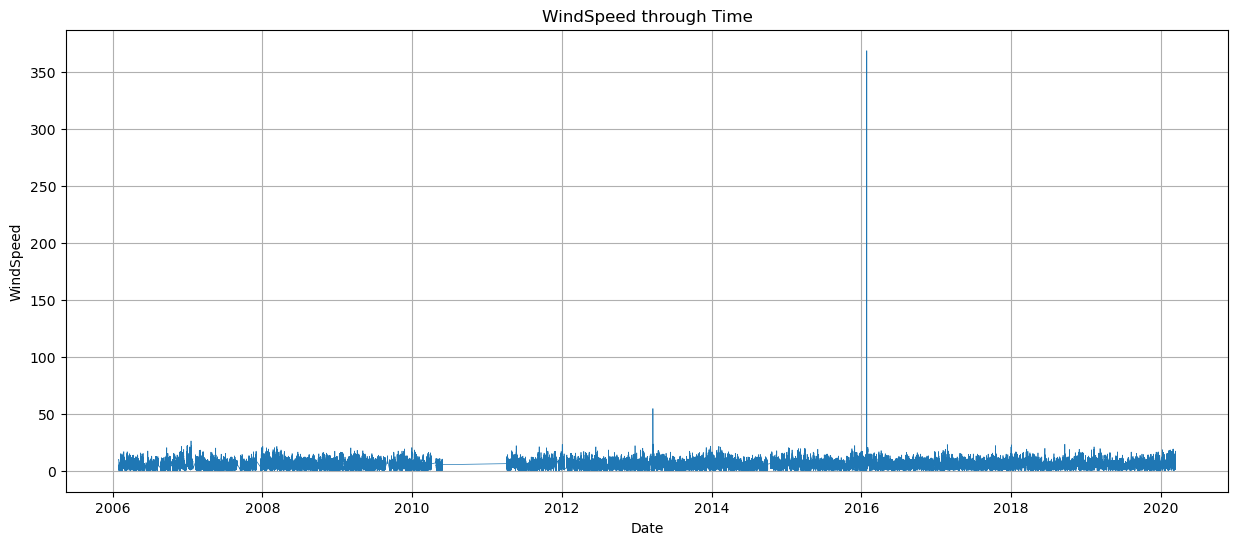

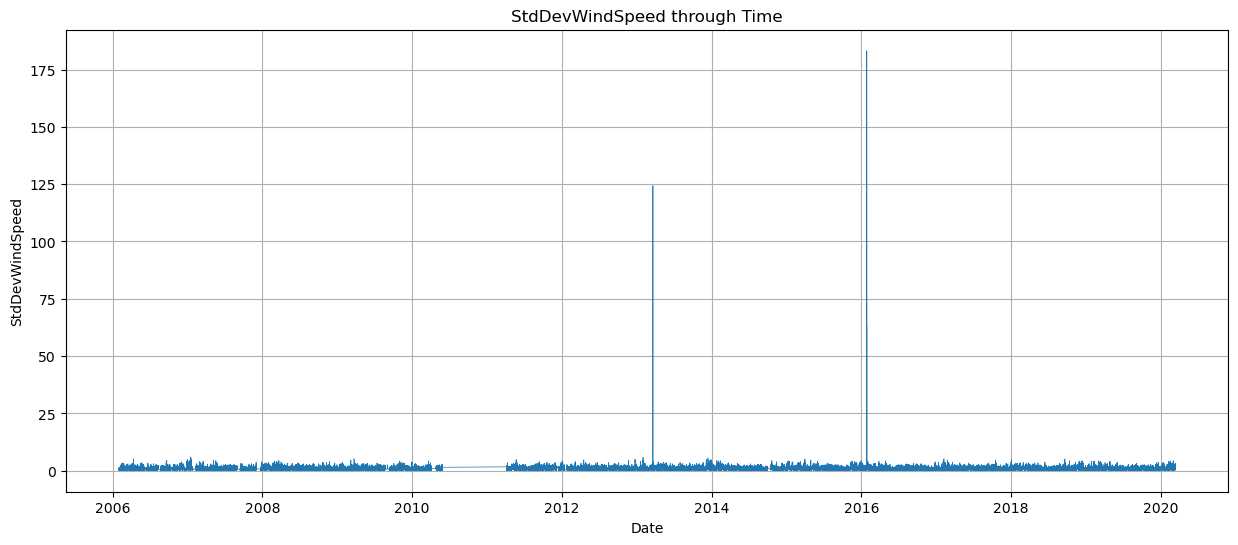

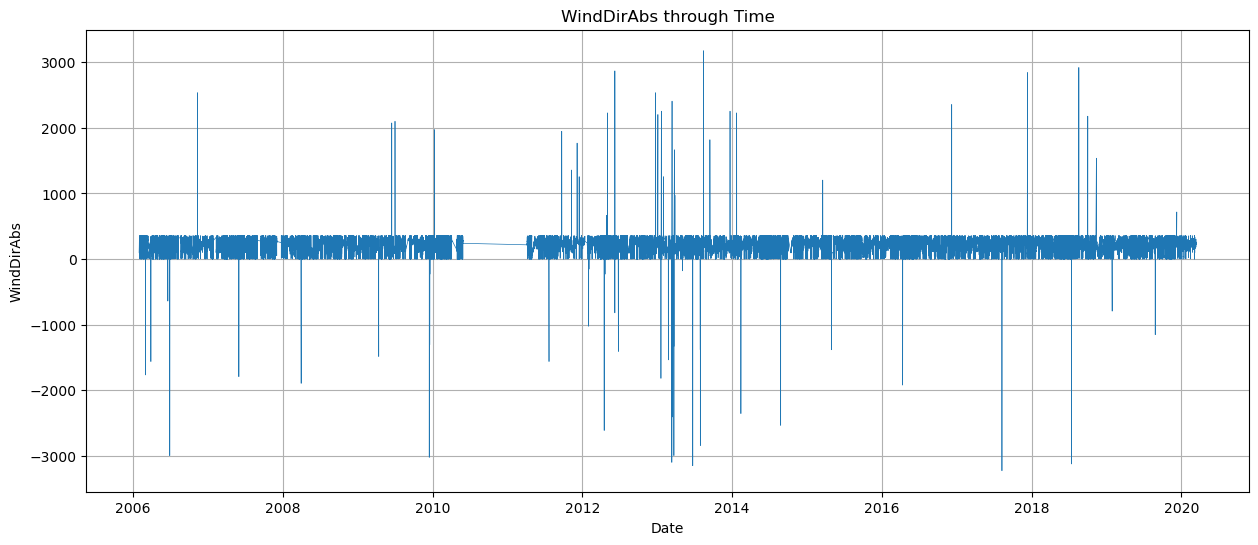

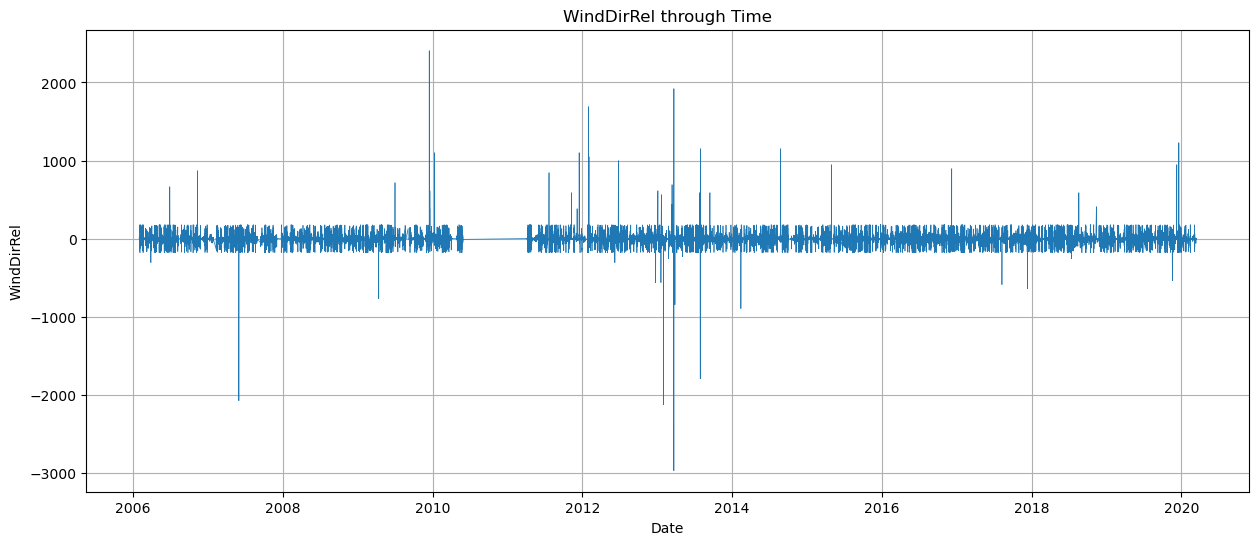

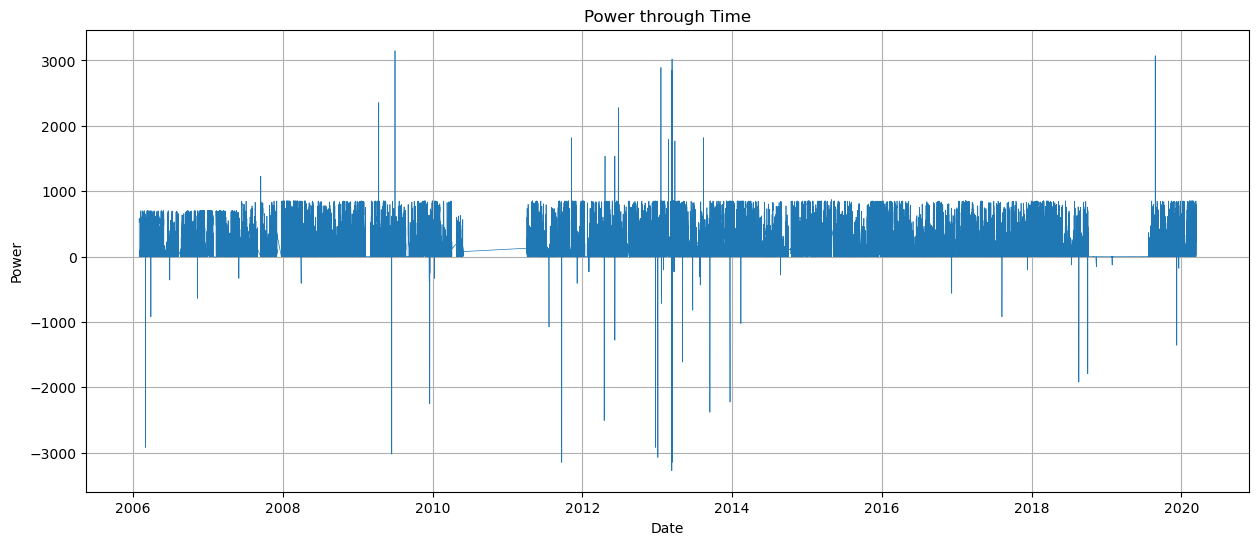

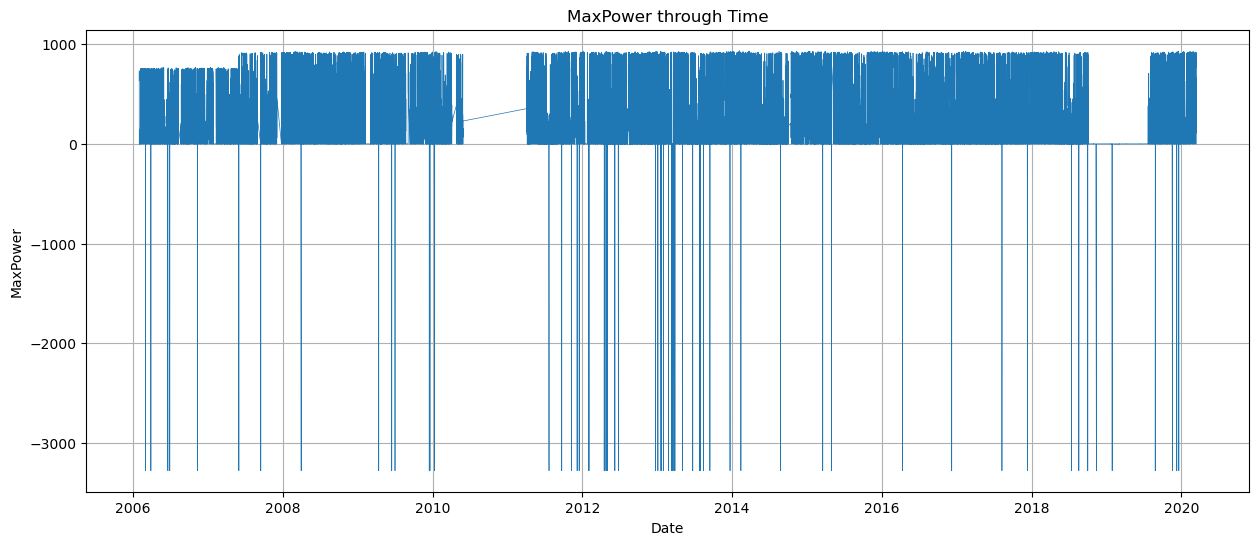

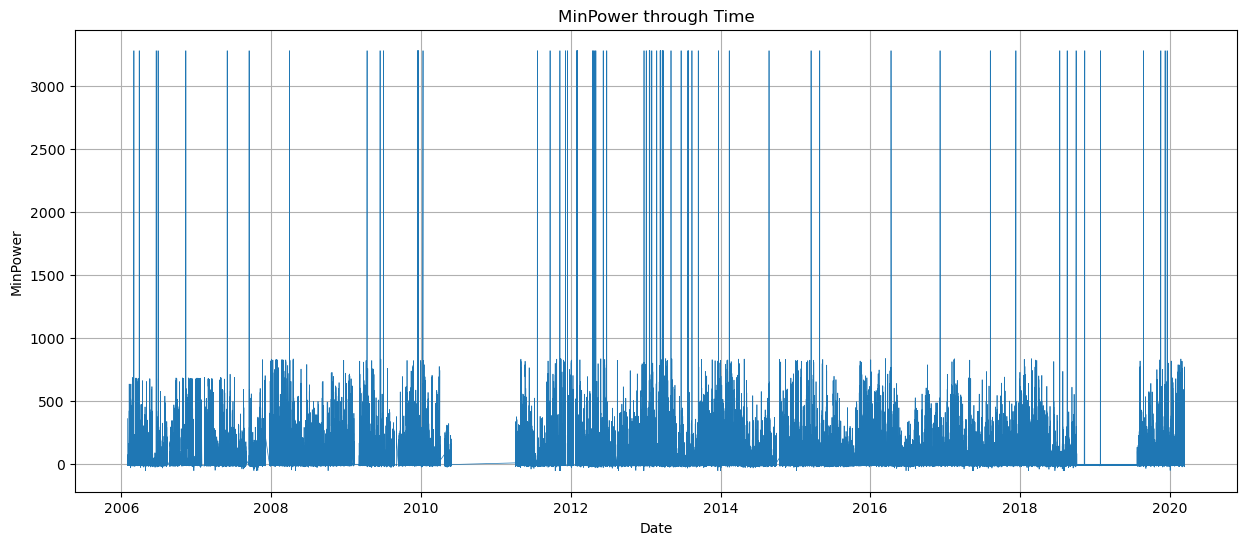

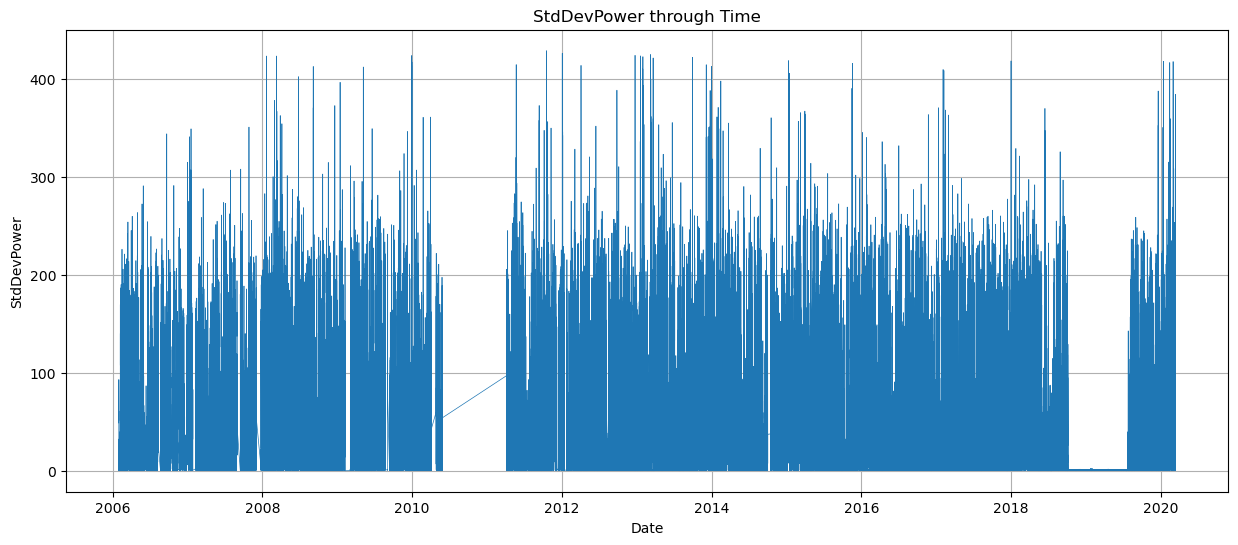

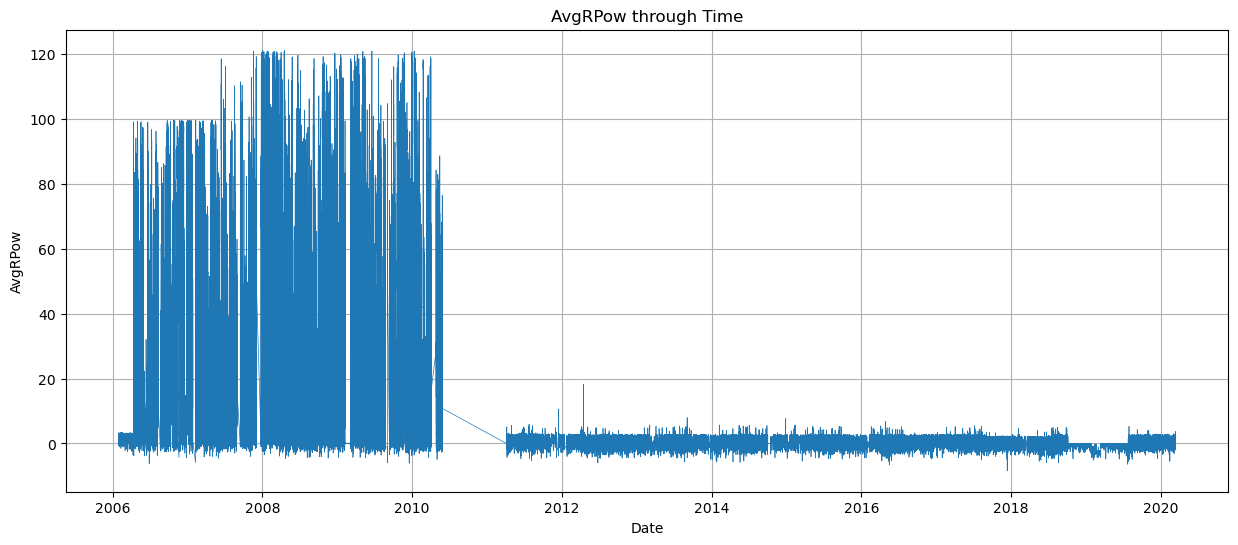

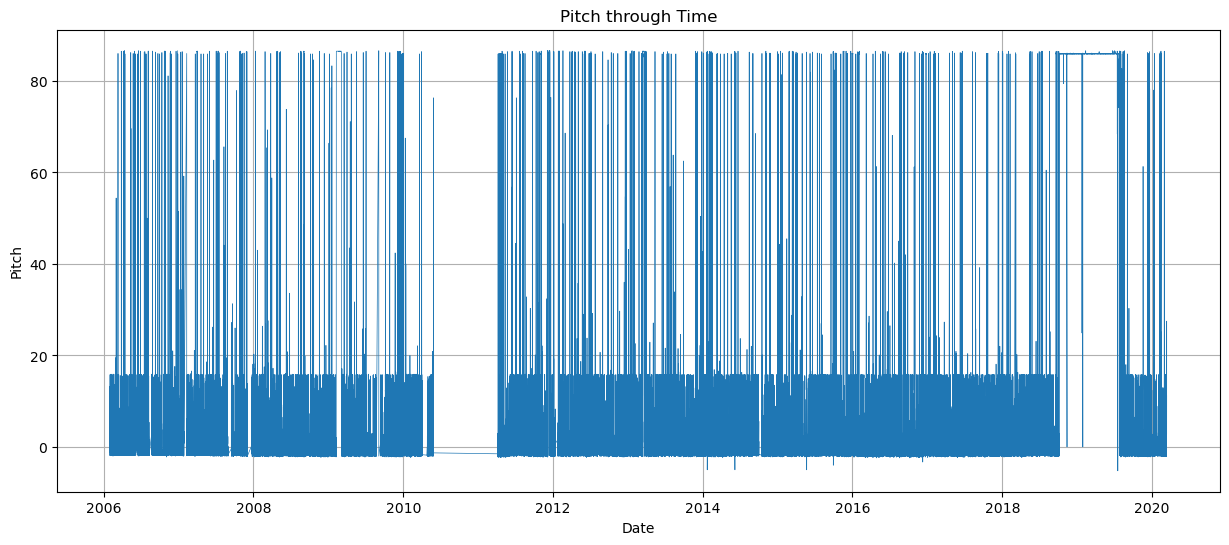

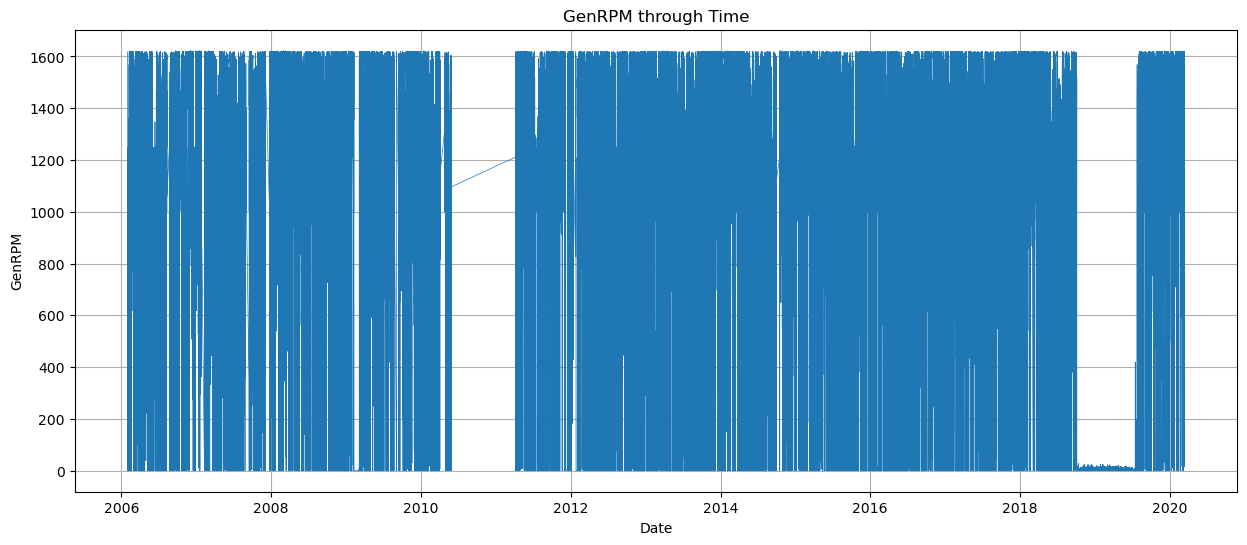

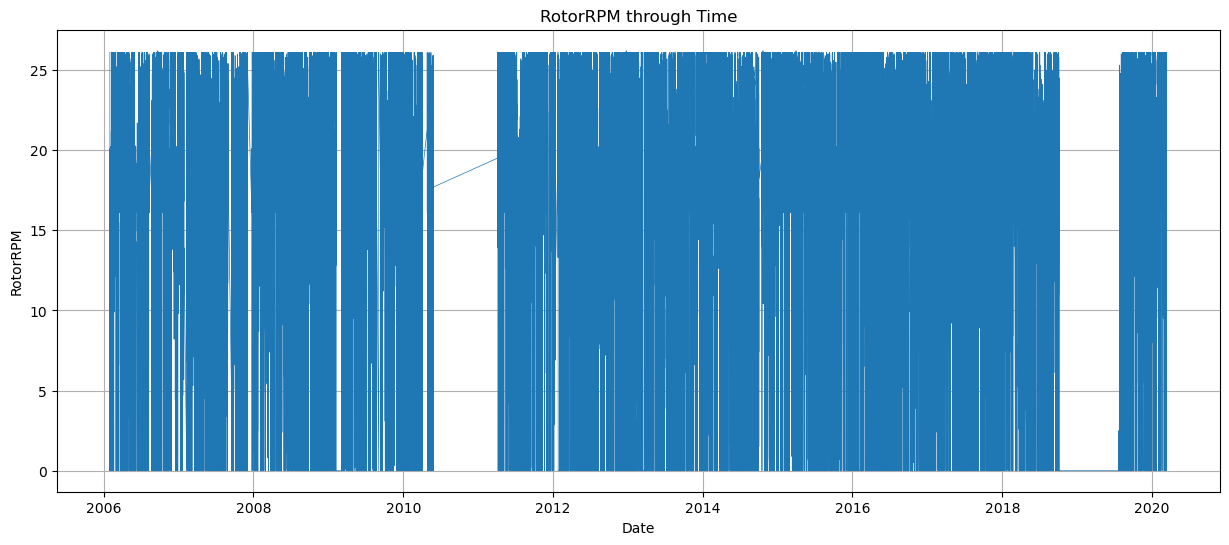

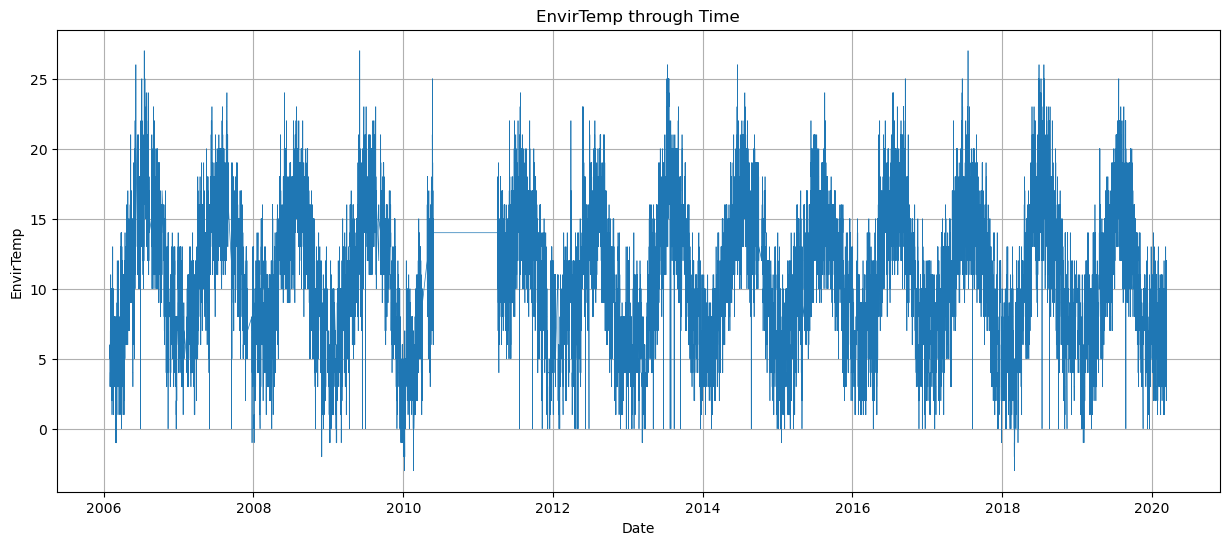

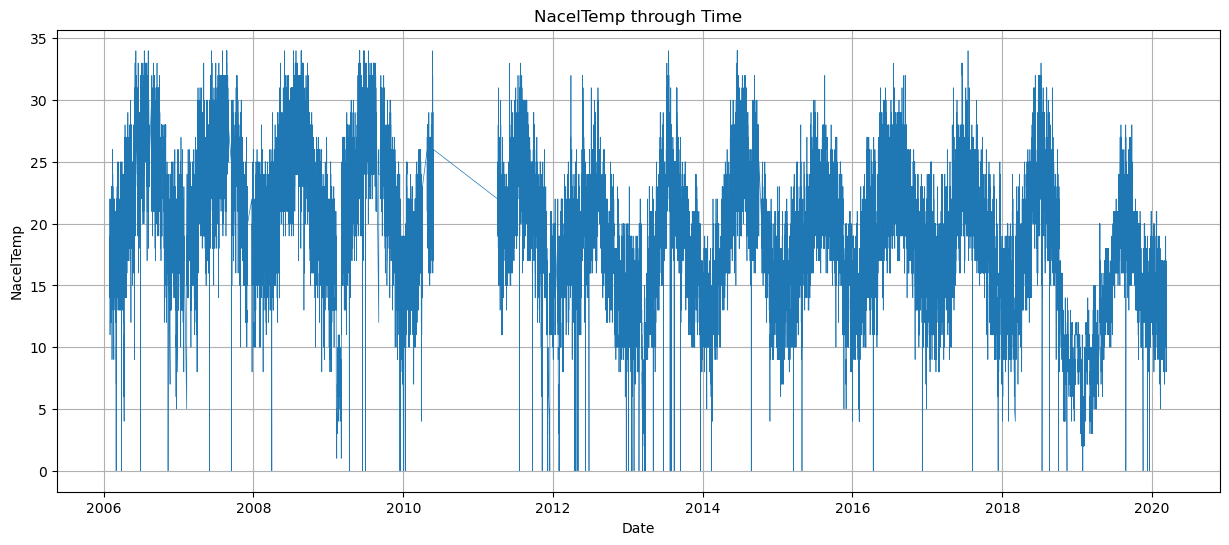

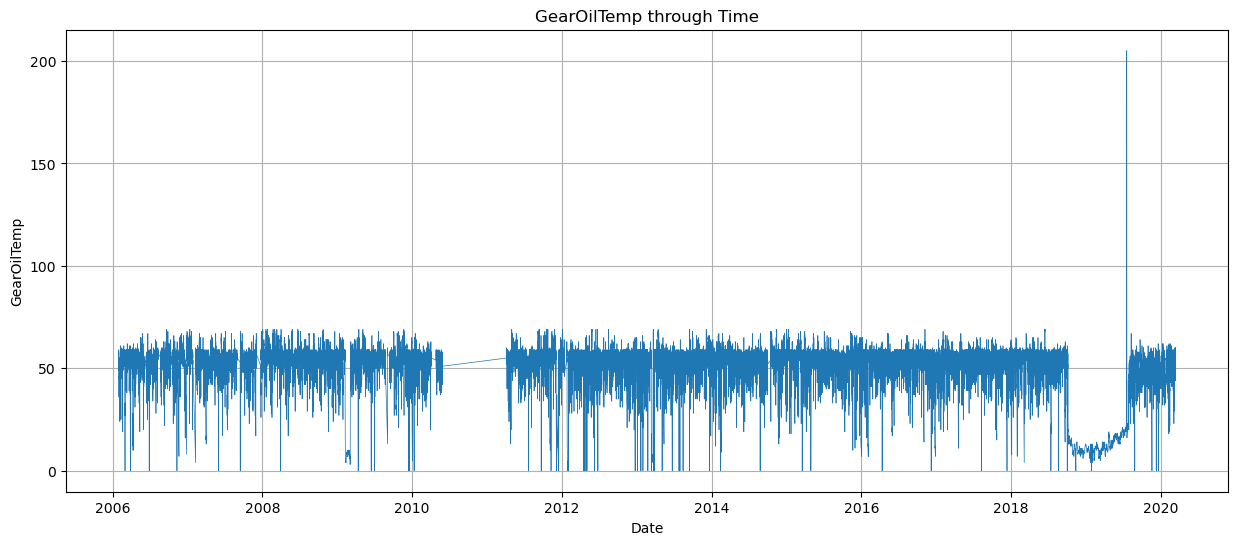

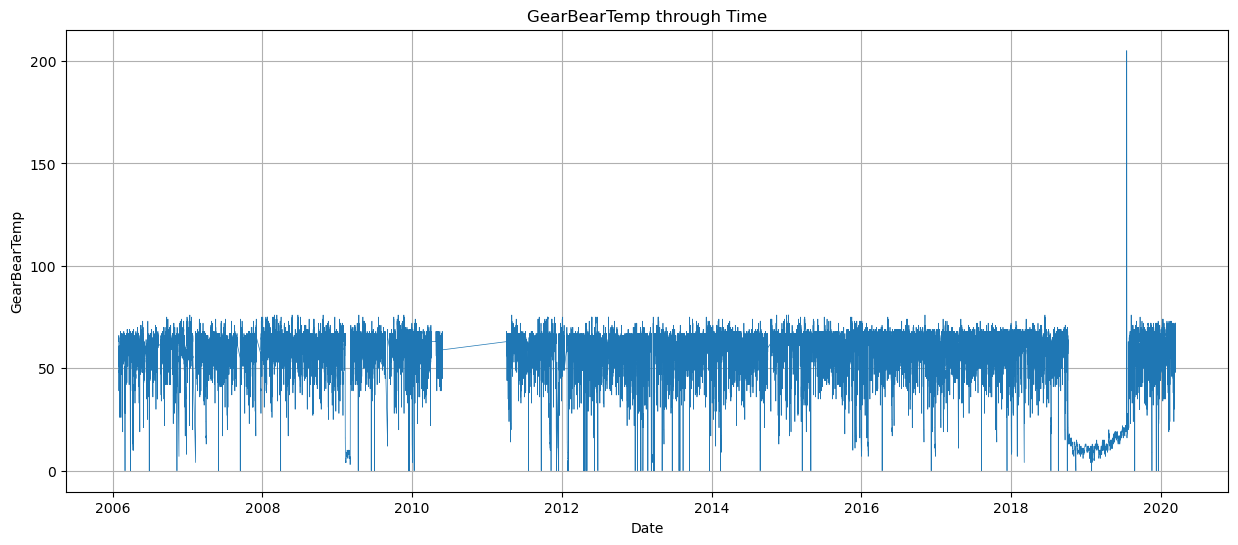

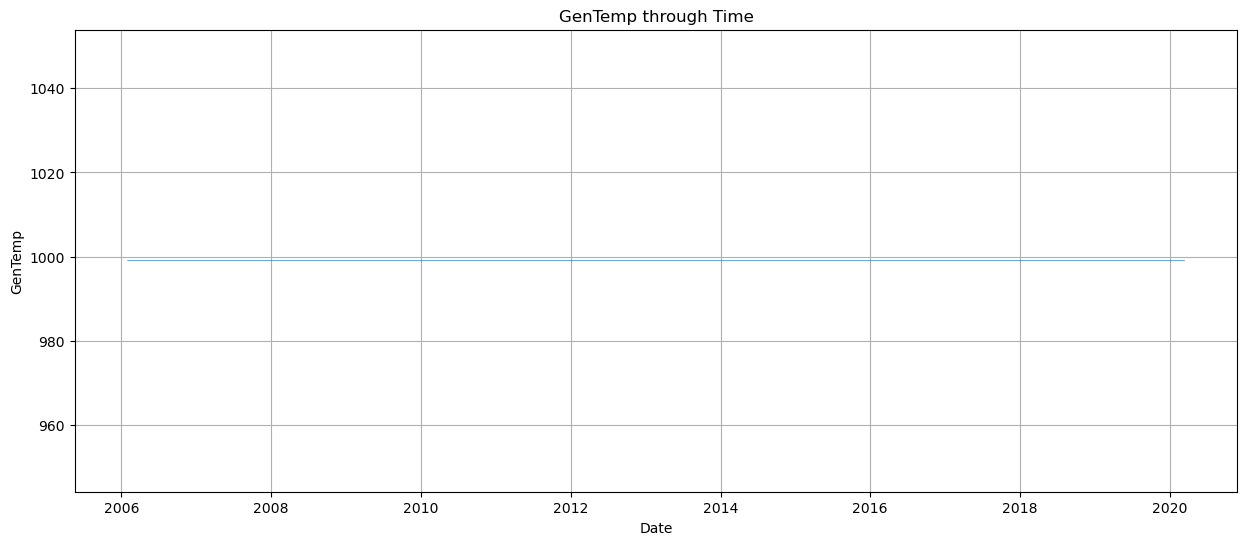

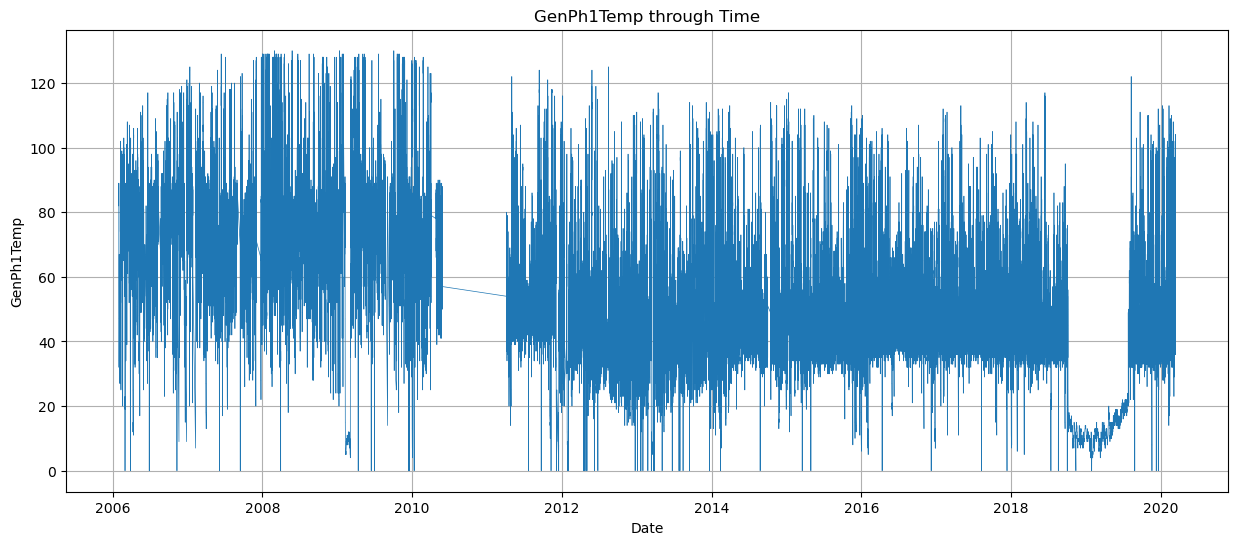

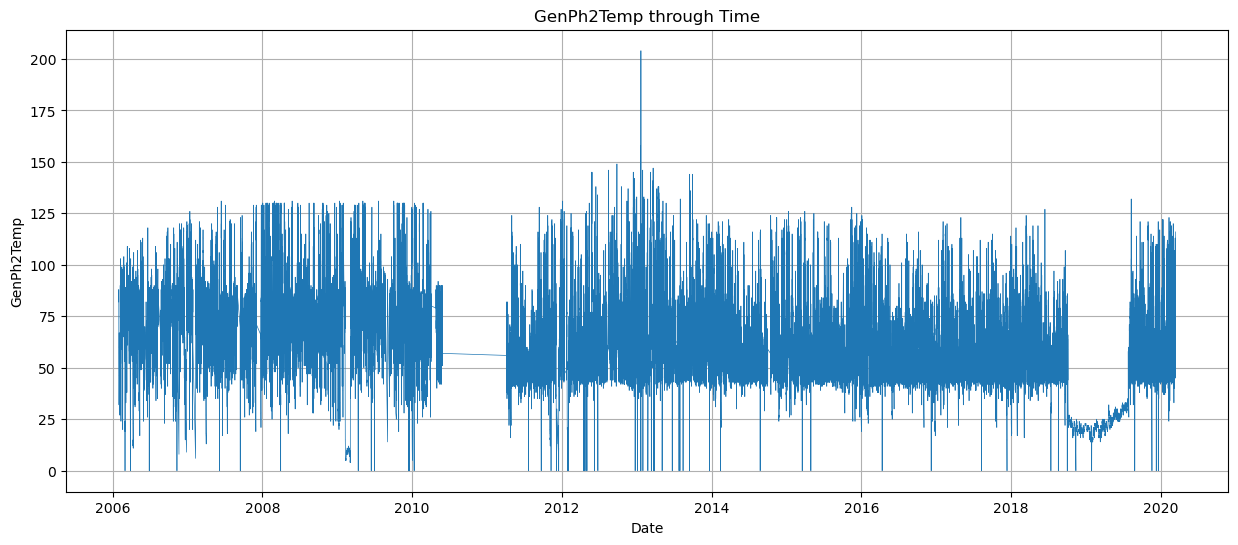

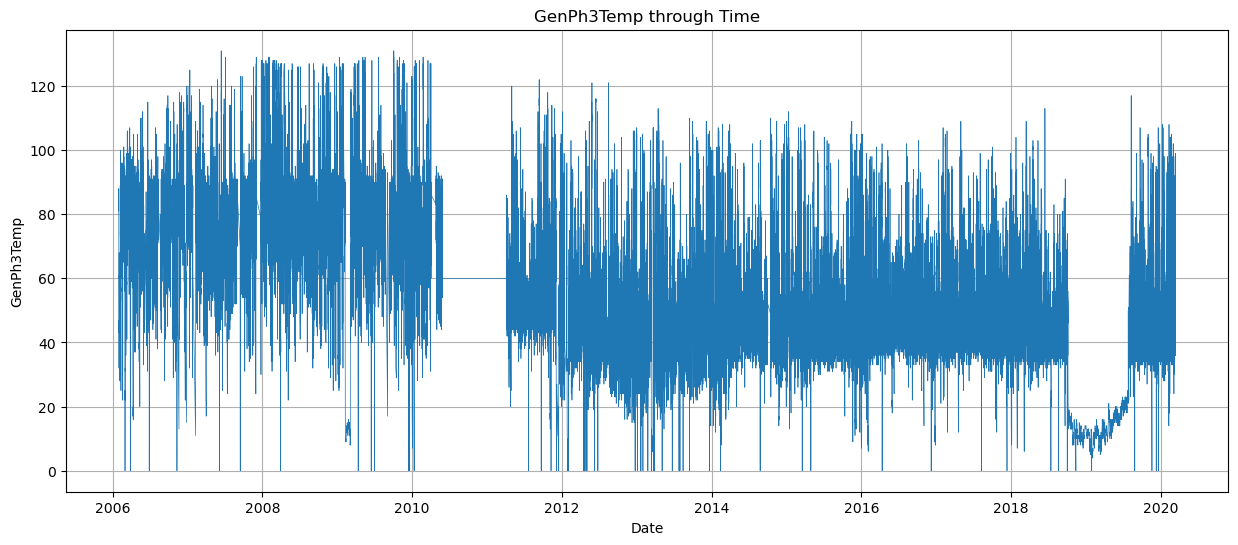

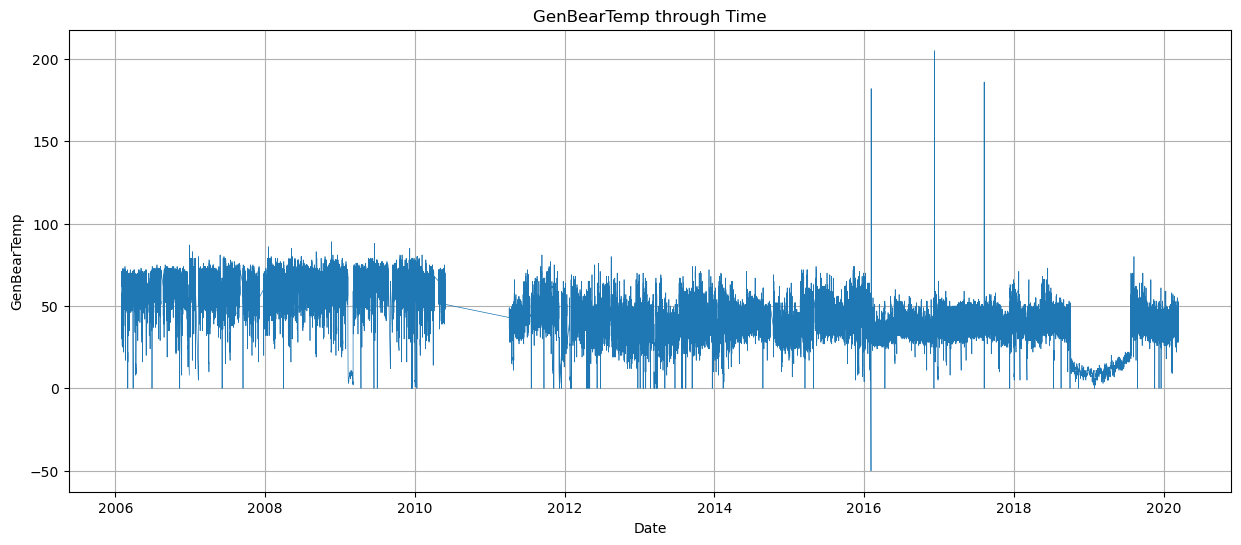

In [13]:
# plotting numerical variables against Time.

for col in df.select_dtypes (include = 'number').columns:
    plt.figure (figsize =(15,6))
    plt.plot(df['Timestamps'], df[col], linewidth=0.5)
    plt.title(f'{col} through Time')
    plt.xlabel('Date')
    plt.ylabel(col)
    plt.grid(True)
    plt.show

## Data Exploration

The variables can be be grouped into 5 categories/dimensions.
1) Wind Speed
2) Wind Direction
3) Power
4) Revolutions per Min(RPM)- Rotor & generator
5) Temperature


#### Wind Speed

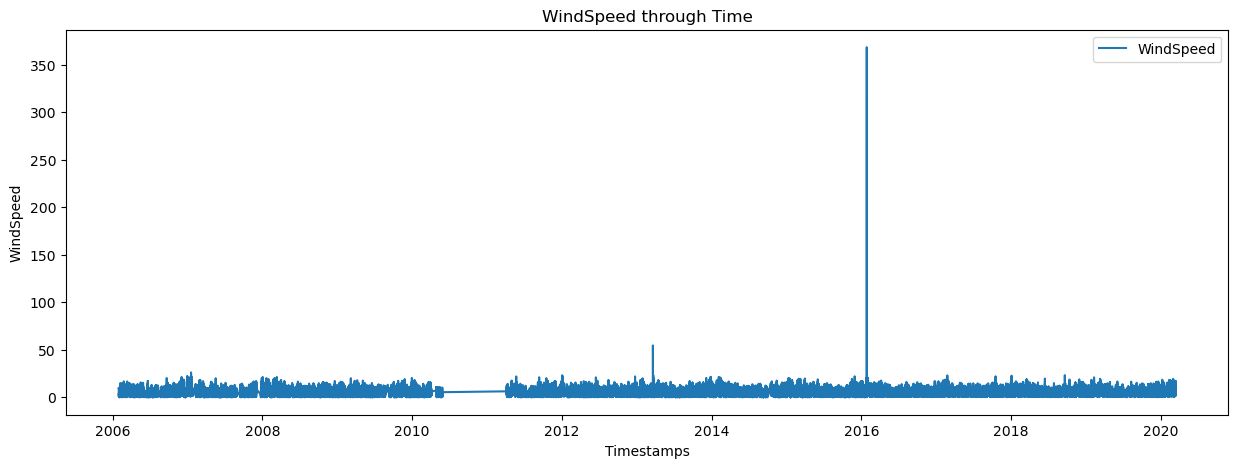

In [14]:
g = df
plt.figure(figsize=(15,5)) 
plt.plot(g["Timestamps"], g["WindSpeed"], label='WindSpeed')
   
plt.xlabel("Timestamps")
plt.ylabel("WindSpeed")
plt.title("WindSpeed through Time")
plt.legend()
plt.show()

There is a sharp spike in Windspeed in early 2016. and a gap between 2010 and 2012

In [15]:
(df['WindSpeed']>300).sum()

np.int64(18)

In [16]:
df.loc[df['WindSpeed']>300,['Timestamps','WindSpeed']]

,Timestamps,WindSpeed
444238,2016-01-27 05:50:00,362.6
444239,2016-01-27 06:00:00,368.4
444240,2016-01-27 06:10:00,368.4
444241,2016-01-27 06:20:00,368.4
444242,2016-01-27 06:30:00,368.4
444243,2016-01-27 06:40:00,368.4
444244,2016-01-27 06:50:00,368.4
444245,2016-01-27 07:00:00,368.4
444246,2016-01-27 07:10:00,368.4
444247,2016-01-27 07:20:00,368.4


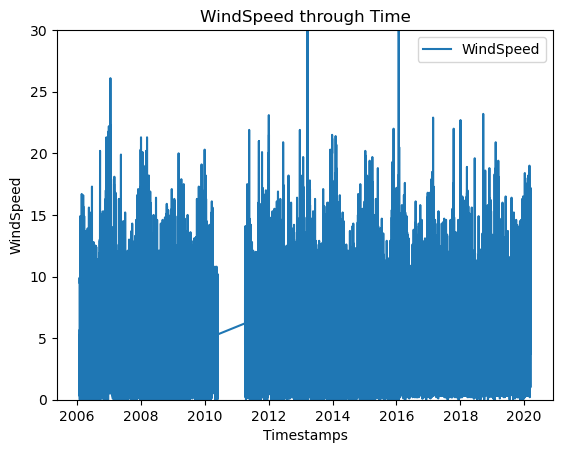

In [17]:
#limiting the windspeed to elimiate the spikes
g = df

plt.plot(g["Timestamps"], g["WindSpeed"], label='WindSpeed')
plt.ylim(0,30)   
plt.xlabel("Timestamps")
plt.ylabel("WindSpeed")
plt.title("WindSpeed through Time")
plt.legend()
plt.show()

the windspeed has season trends/pattern through the years.

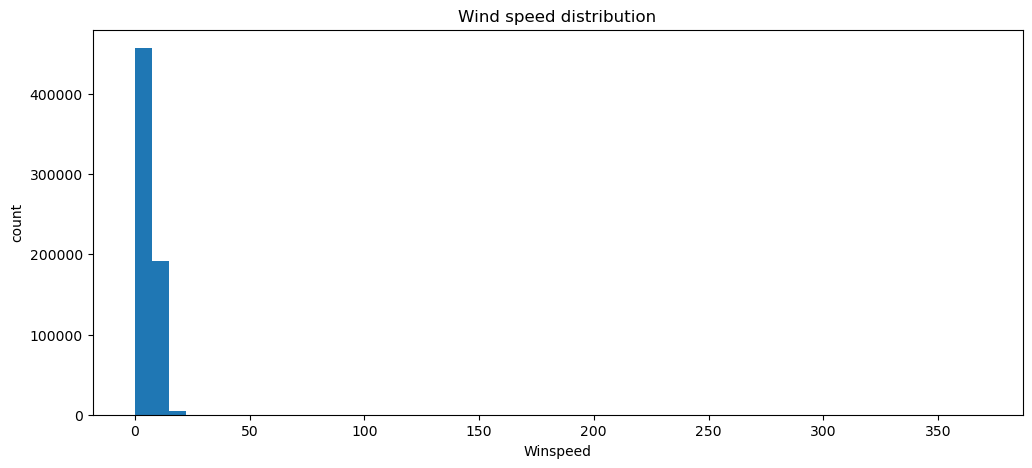

<function matplotlib.pyplot.figure(num: 'int | str | Figure | SubFigure | None' = None, figsize: 'ArrayLike | None' = None, dpi: 'float | None' = None, *, facecolor: 'ColorType | None' = None, edgecolor: 'ColorType | None' = None, frameon: 'bool' = True, FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>, clear: 'bool' = False, **kwargs) -> 'Figure'>

In [18]:
#Histogram
plt.figure(figsize=(12,5))
plt.hist(df.WindSpeed, bins = 50,)
plt.ylabel ('count', fontsize= 10)
plt.xlabel ('Winspeed', fontsize= 10)
plt.title('Wind speed distribution')
plt.show()
plt.figure


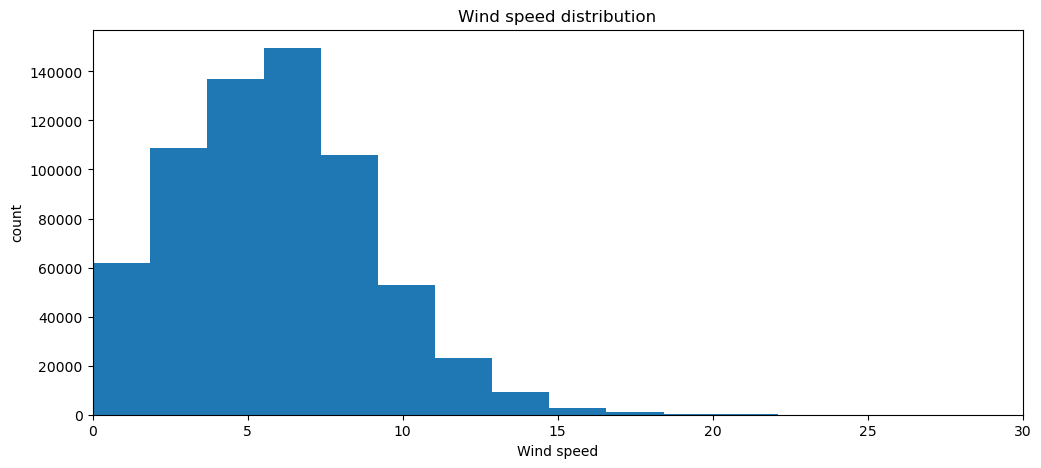

<function matplotlib.pyplot.figure(num: 'int | str | Figure | SubFigure | None' = None, figsize: 'ArrayLike | None' = None, dpi: 'float | None' = None, *, facecolor: 'ColorType | None' = None, edgecolor: 'ColorType | None' = None, frameon: 'bool' = True, FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>, clear: 'bool' = False, **kwargs) -> 'Figure'>

In [19]:
#Histogram (limiting windspeed to 30m/s)
plt.figure(figsize=(12,5))
plt.hist(df.WindSpeed, bins = 200,)

plt.xlim(0,30)
plt.ylabel ('count', fontsize= 10)
plt.xlabel ('Wind speed', fontsize= 10)
plt.title('Wind speed distribution')
plt.show()
plt.figure

The windspeed is right skewed and the most frequent speeds are betweed 5 and 7 m/s- with over 140,000 occurences of the highest bin.

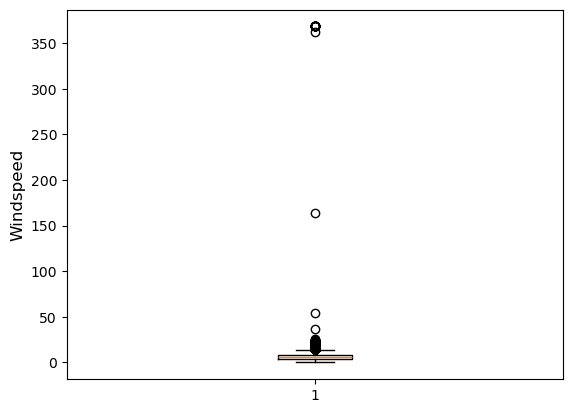

In [20]:
plt.boxplot(df.WindSpeed)
plt.ylabel ('Windspeed', fontsize= 12)
plt.show()

In [21]:
df['WindSpeed'].describe()

count    653103.000000
mean          5.889332
std           3.642553
min           0.000000
25%           3.500000
50%           5.800000
75%           7.800000
max         368.400000
Name: WindSpeed, dtype: float64

#### Wind Speed Standard Deviation
This is basically the measure of fluctuation in windspeed 

In [22]:
df['StdDevWindSpeed'].describe()

count    653103.000000
mean          0.925126
std           0.603657
min           0.000000
25%           0.500000
50%           0.900000
75%           1.200000
max         183.200000
Name: StdDevWindSpeed, dtype: float64

the max StdDevWindSpeed very far off 

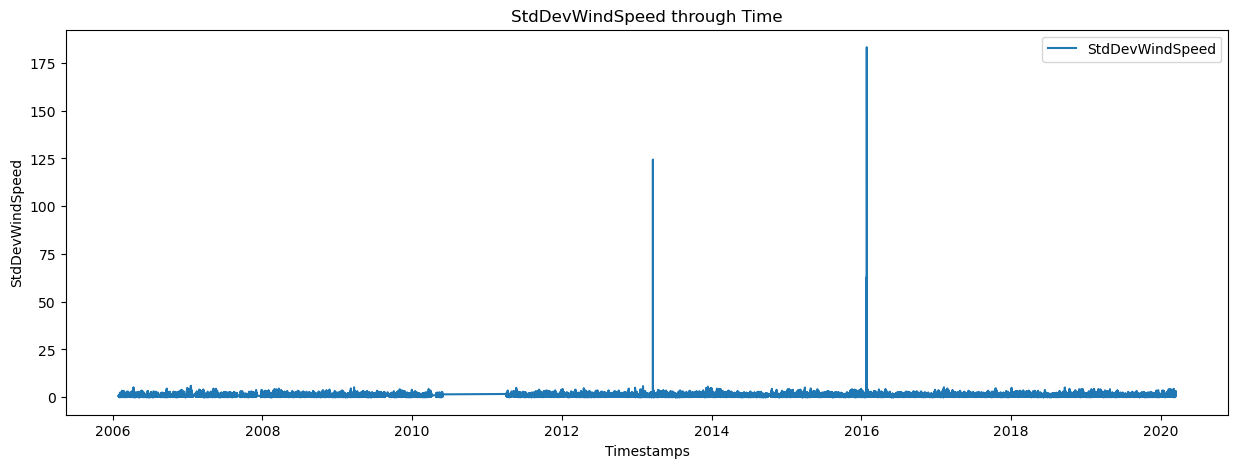

In [23]:
g = df
plt.figure(figsize=(15,5)) 
plt.plot(g["Timestamps"], g["StdDevWindSpeed"], label='StdDevWindSpeed')
   
plt.xlabel("Timestamps")
plt.ylabel("StdDevWindSpeed")
plt.title("StdDevWindSpeed through Time")
plt.legend()
plt.show()

the spikes occur in the same period as the spikes in windspeed

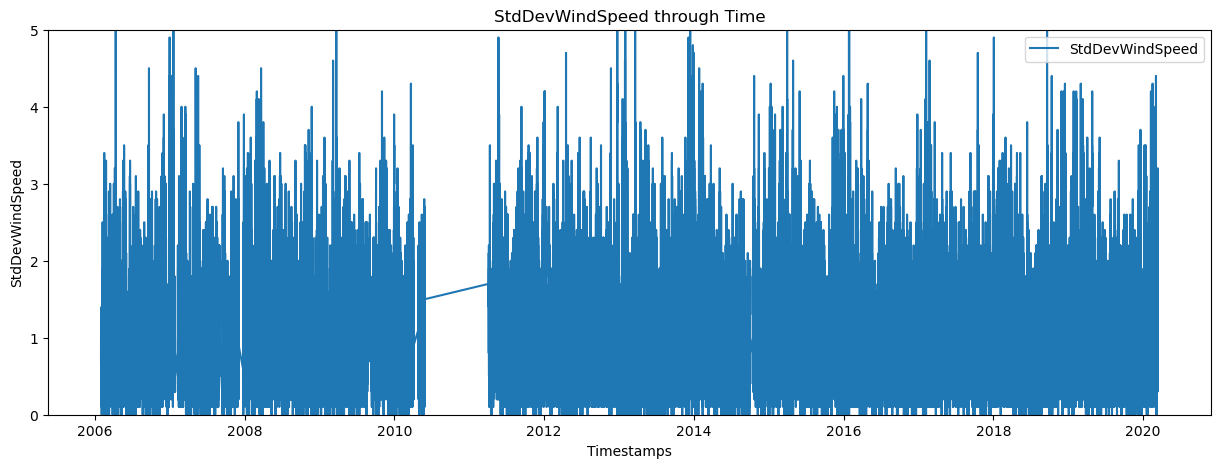

In [24]:
#limiting the StdDevWindSpeed to elimiate the spikes
g = df
plt.figure(figsize=(15,5)) 
plt.plot(g["Timestamps"], g["StdDevWindSpeed"], label='StdDevWindSpeed')
plt.ylim(0,5)   
plt.xlabel("Timestamps")
plt.ylabel("StdDevWindSpeed")
plt.title("StdDevWindSpeed through Time")
plt.legend()
plt.show()

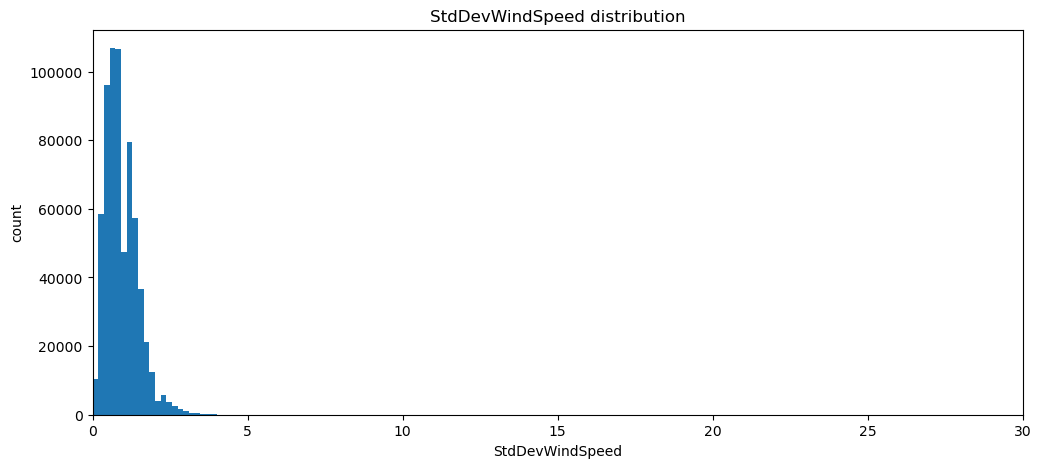

<function matplotlib.pyplot.figure(num: 'int | str | Figure | SubFigure | None' = None, figsize: 'ArrayLike | None' = None, dpi: 'float | None' = None, *, facecolor: 'ColorType | None' = None, edgecolor: 'ColorType | None' = None, frameon: 'bool' = True, FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>, clear: 'bool' = False, **kwargs) -> 'Figure'>

In [25]:
#Histogram (limiting windspeed to 30m/s)
plt.figure(figsize=(12,5))
plt.hist(df.StdDevWindSpeed, bins = 1000,)

plt.xlim(0,30)
plt.ylabel ('count', fontsize= 10)
plt.xlabel ('StdDevWindSpeed', fontsize= 10)
plt.title('StdDevWindSpeed distribution')
plt.show()
plt.figure

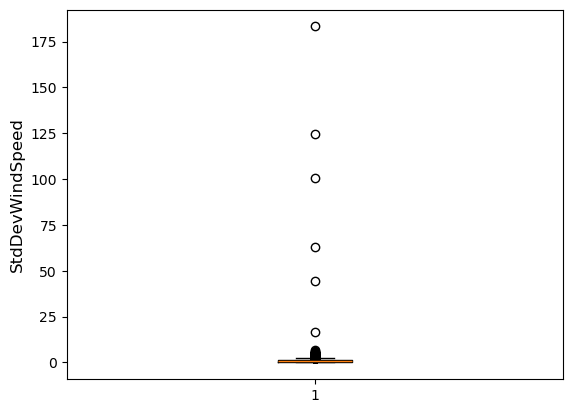

In [26]:
plt.boxplot(df.StdDevWindSpeed)
plt.ylabel ('StdDevWindSpeed', fontsize= 12)
plt.show()

In [27]:
df['StdDevWindSpeed'].describe()

count    653103.000000
mean          0.925126
std           0.603657
min           0.000000
25%           0.500000
50%           0.900000
75%           1.200000
max         183.200000
Name: StdDevWindSpeed, dtype: float64

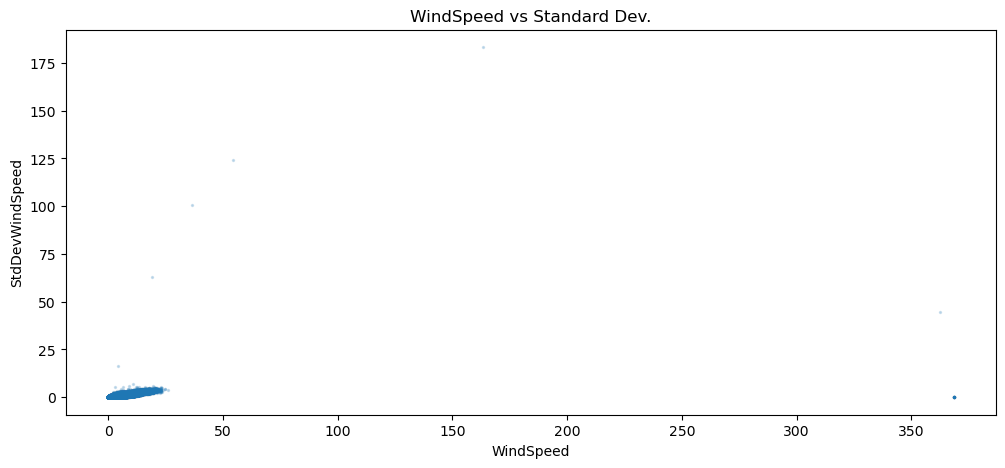

In [28]:
#Scatter Plot of Winspeed vs Standard deviation
plt.figure(figsize=(12,5))
plt.scatter(df['WindSpeed'],df['StdDevWindSpeed'], alpha=0.2, s=2)

plt.ylabel ('StdDevWindSpeed', fontsize= 10)
plt.xlabel ('WindSpeed', fontsize= 10)
plt.title('WindSpeed vs Standard Dev.')
plt.show()

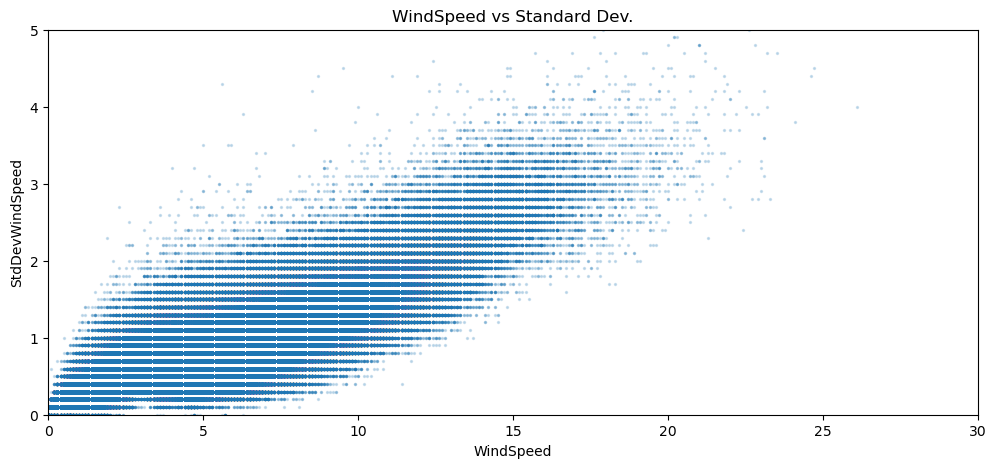

In [29]:
#Scatter Plot of Winspeed vs Standard deviation (limiting to exclude spikes)
plt.figure(figsize=(12,5))
plt.scatter(df['WindSpeed'],df['StdDevWindSpeed'], alpha=0.2, s=2)

plt.ylabel ('StdDevWindSpeed', fontsize= 10)
plt.xlabel ('WindSpeed', fontsize= 10)
plt.title('WindSpeed vs Standard Dev.')
plt.xlim(0,30)
plt.ylim(0,5)
plt.show()


In [30]:
#checking the relationship between windspeed and windspeed standard dev.
df[['WindSpeed','StdDevWindSpeed']].corr()


,WindSpeed,StdDevWindSpeed
WindSpeed,1.000000,0.608971
StdDevWindSpeed,0.608971,1.000000


There is a strong correlation between windspeed and windspeed standard deviation

### Wind Direction

In [31]:
df[['WindDirAbs','WindDirRel']].describe()

,WindDirAbs,WindDirRel
count,653103.00000,653103.000000
mean,211.09934,-0.494550
std,90.68637,25.370729
min,-3224.70000,-2969.200000
25%,143.30000,-2.400000
50%,231.70000,0.000000
75%,278.20000,2.500000
max,3175.00000,2406.400000


the Minimum values and maximum values are not valid figures (i.e they are outside the 360 degree range)

In [32]:
df[['WindDirAbs','WindDirRel']].describe().drop(['min','max'])

,WindDirAbs,WindDirRel
count,653103.00000,653103.000000
mean,211.09934,-0.494550
std,90.68637,25.370729
25%,143.30000,-2.400000
50%,231.70000,0.000000
75%,278.20000,2.500000


In [33]:
# AI was used for the below prompt.

df.loc[(df['WindDirAbs'].between(0,360)) & (df['WindDirRel'].between(-180,180)), ['WindDirAbs','WindDirRel']].describe()

,WindDirAbs,WindDirRel
count,653028.000000,653028.000000
mean,211.120716,-0.505155
std,88.292612,23.417423
min,0.000000,-180.000000
25%,143.300000,-2.400000
50%,231.700000,0.000000
75%,278.200000,2.500000
max,359.900000,179.900000


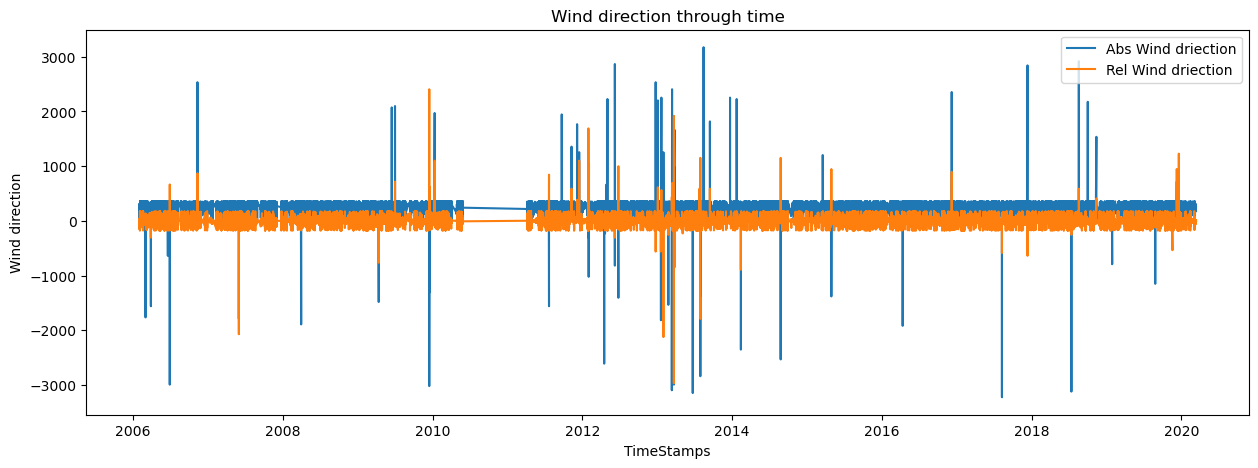

In [34]:
plt.figure(figsize=(15,5))
plt.plot(df['Timestamps'], df['WindDirAbs'], label = 'Abs Wind driection')
plt.plot(df['Timestamps'], df['WindDirRel'], label = 'Rel Wind driection')
plt.ylabel ('Wind direction', fontsize= 10)
plt.xlabel ('TimeStamps', fontsize= 10)
plt.title('Wind direction through time')
plt.legend()
plt.show()

There are alot of instances of unusual readings in wind direction. this wil need further investigation.

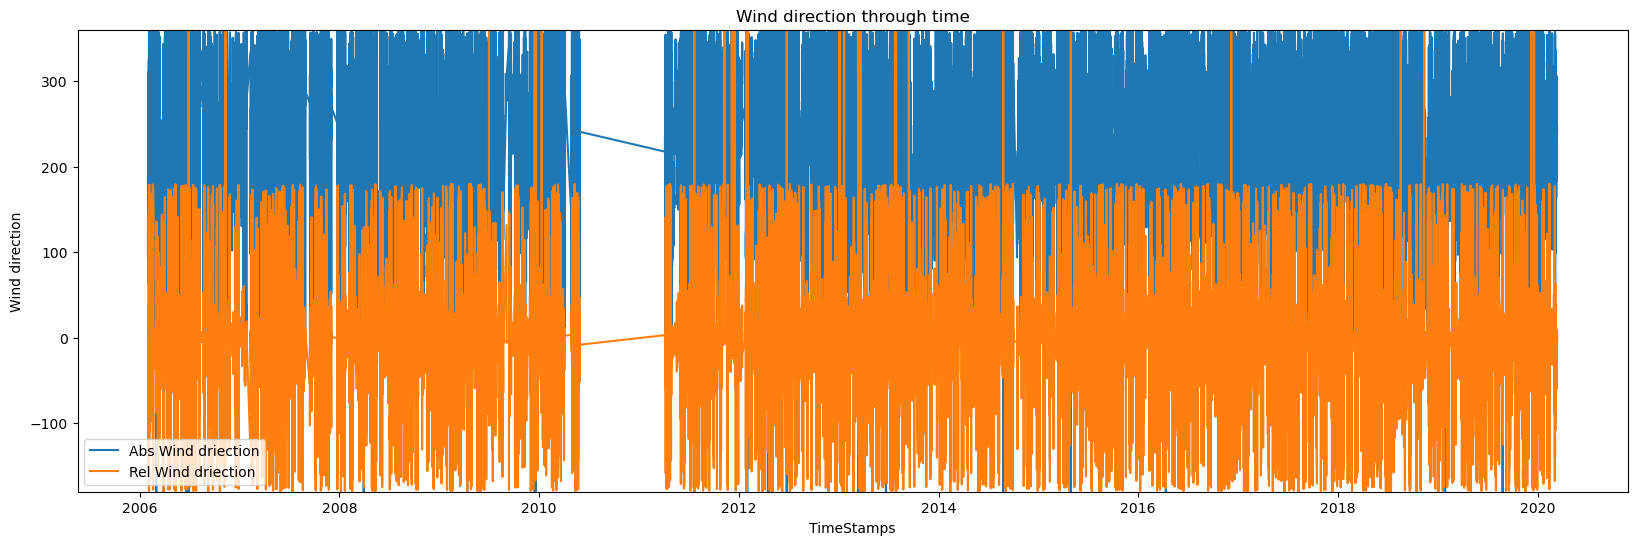

In [35]:
# limiting to exclude unusal min and max
plt.figure(figsize=(20,6))
plt.plot(df['Timestamps'], df['WindDirAbs'], label = 'Abs Wind driection')
plt.plot(df['Timestamps'], df['WindDirRel'], label = 'Rel Wind driection')
plt.ylim(-180,360)
plt.ylabel ('Wind direction', fontsize= 10)
plt.xlabel ('TimeStamps', fontsize= 10)
plt.title('Wind direction through time')
plt.legend()
plt.show()

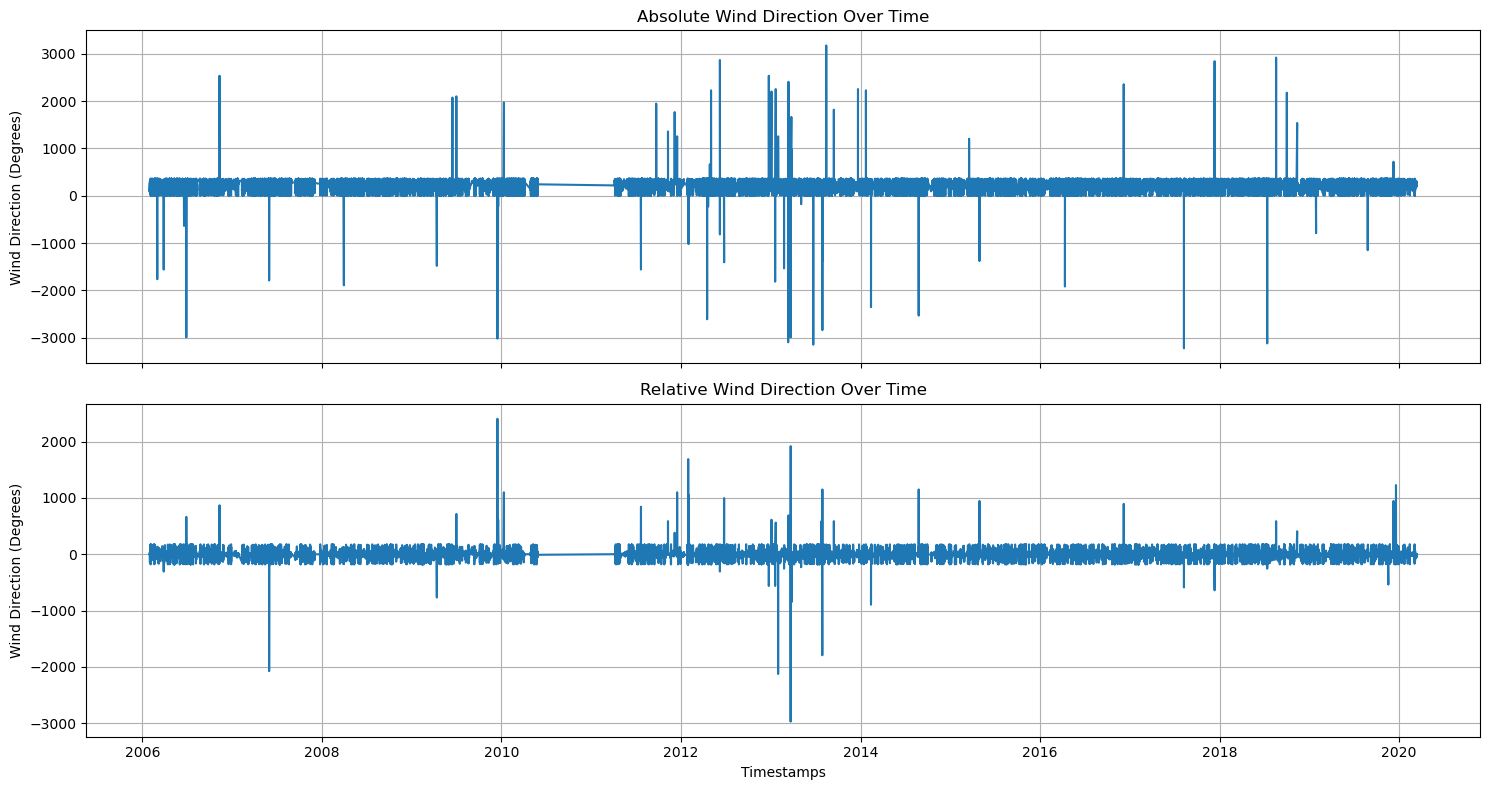

In [36]:
# Ai was used for this prompt - to display seperate plots

fig, ax = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Plot A - Absolute Wind Direction
ax[0].plot(df['Timestamps'], df['WindDirAbs'])
ax[0].set_title('Absolute Wind Direction Over Time')
ax[0].set_ylabel('Wind Direction (Degrees)')
ax[0].grid(True)

# Plot B - Relative Wind Direction
ax[1].plot(df['Timestamps'], df['WindDirRel'])
ax[1].set_title('Relative Wind Direction Over Time')
ax[1].set_xlabel('Timestamps')
ax[1].set_ylabel('Wind Direction (Degrees)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

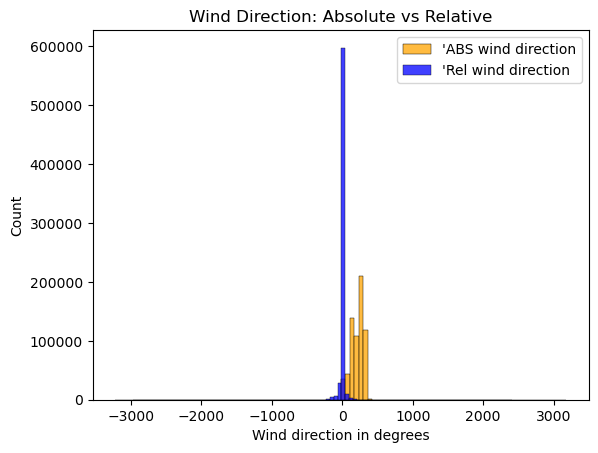

In [37]:
sns.histplot(df['WindDirAbs'],bins=100, color="orange",label="'ABS wind direction")
sns.histplot(df['WindDirRel'],bins=100, color="blue",label="'Rel wind direction")
plt.legend()
plt.xlabel("Wind direction in degrees")
plt.ylabel("Count")
plt.title("Wind Direction: Absolute vs Relative")
plt.legend()
plt.show()

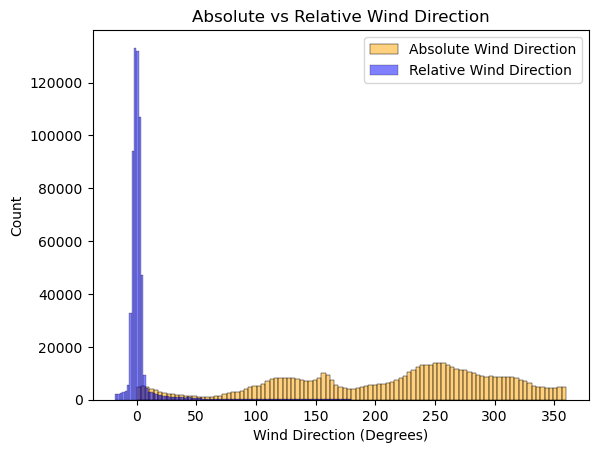

In [38]:

sns.histplot(df.loc[df['WindDirAbs'].between(0,360), 'WindDirAbs'], bins=100, alpha=0.5, color='orange', label='Absolute Wind Direction')
sns.histplot(df.loc[df['WindDirRel'].between(-18,180), 'WindDirRel'], bins=100, alpha=0.5, color='blue', label='Relative Wind Direction')

plt.xlabel('Wind Direction (Degrees)')
plt.ylabel('Count')
plt.title('Absolute vs Relative Wind Direction')
plt.legend()
plt.show()


Although the absolute wind direction ranged from 0 to 360 degrees, the relative wind diretion stays below 50degrees. This shows the trubine is always turend into the wind.

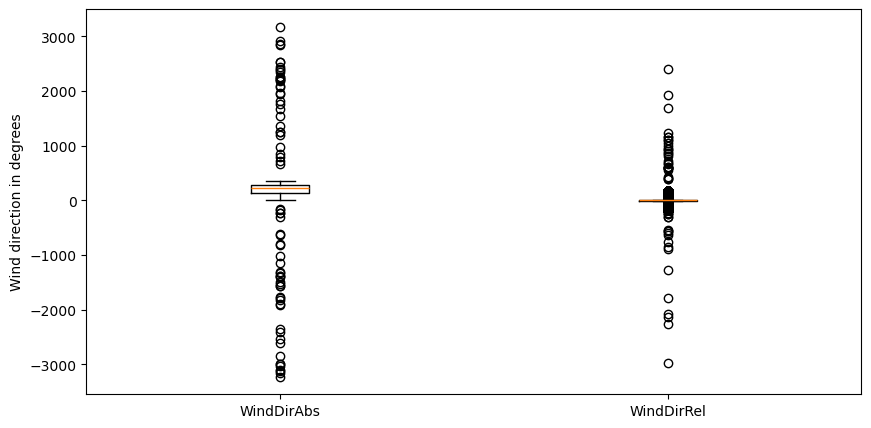

In [39]:
plt.figure(figsize=(10,5))
plt.boxplot ([df['WindDirAbs'], df['WindDirRel']])
plt.xticks([1,2], ['WindDirAbs','WindDirRel'])
plt.ylabel("Wind direction in degrees",fontsize=10)
plt.show()

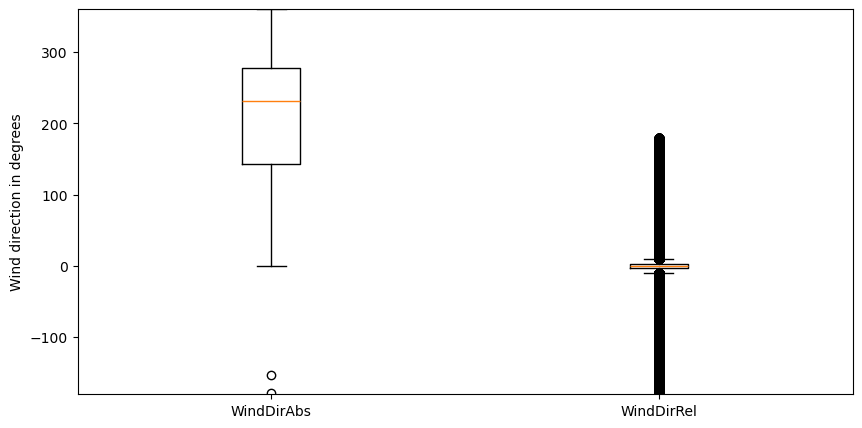

In [40]:
plt.figure(figsize=(10,5))
plt.boxplot ([df['WindDirAbs'], df['WindDirRel']])
plt.ylim(-180,360)
plt.xticks([1,2], ['WindDirAbs','WindDirRel'])
plt.ylabel("Wind direction in degrees",fontsize=10)
plt.show()

the boplots give the same result as the histograms- indicating the relative wind direction is narrow.

In [41]:
%pip install windrose
import matplotlib.pyplot as plt
from windrose import WindroseAxes

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


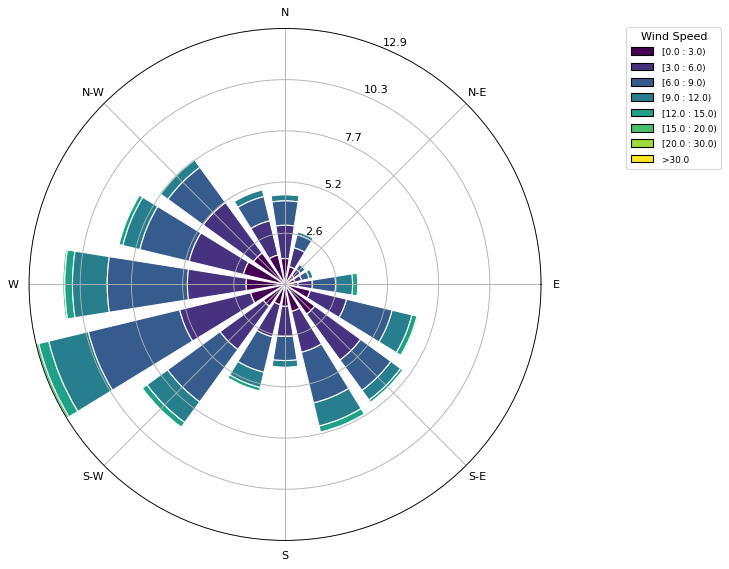

In [42]:
#Ai was used for the  windrose prompt below


# Filter values for the wind rose
wind = df.loc[
    df['WindDirAbs'].between(0,360) &
    df['WindSpeed'].between(0,30)
]

# Create wind rose
ax = WindroseAxes.from_ax(figsize=(10,8))

ax.bar(
    wind['WindDirAbs'],
    wind['WindSpeed'],
    bins=[0,3,6,9,12,15,20,30],
    normed=True,
    opening=0.8,
    edgecolor='white'
)

ax.set_legend(title='Wind Speed')
ax.set_legend(title='Wind Speed', loc='upper right', bbox_to_anchor=(1.35, 1.0))

plt.show()

The wind is mostly from the west- the strongest gusts coming from between the west and southwest
the North east has the least wind speed.

### Power generation

In [43]:
df[['Power','MaxPower','MinPower','StdDevPower','AvgRPow' ]].describe()

,Power,MaxPower,MinPower,StdDevPower,AvgRPow
count,653103.000000,653103.000000,653103.000000,653103.000000,653103.000000
mean,165.549605,267.409000,68.219187,43.281565,7.265617
std,214.781048,304.234889,121.350558,50.959072,19.637154
min,-3274.900000,-3276.800000,-50.400000,0.000000,-8.400000
25%,-0.700000,-0.600000,-5.200000,0.700000,0.000000
50%,77.500000,143.400000,18.400000,23.200000,0.000000
75%,242.200000,448.600000,92.000000,68.000000,0.500000
max,3149.100000,933.000000,3276.700000,428.400000,121.100000


The Minimum of Maxpower (-3276.8) is less than the minimum of Minpower (-50.4) 
and the maximum of MinPower (3276.7) is higher that the maximum of MaxPower (933.0)

For power, the mean (165.55kw) is much more higher than the median- this indicates a positive skew.<br>
a -ve lower quantile shows there are some -ve readings- this indicate power consumption ( not power generation).<br>
and, a max of 3149kw is not a feasible reading for a machine of this size ( one signle wind turbine).

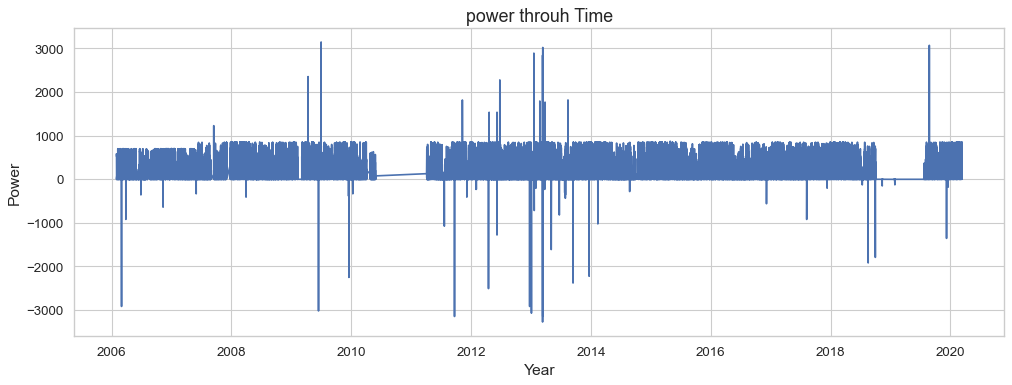

In [56]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15,5), dpi=80)

sns.lineplot(data=df,
             x="Timestamps",
             y="Power",
             estimator=None)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Power', fontsize=14)
plt.title( 'Power through Time', fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend()
plt.show()

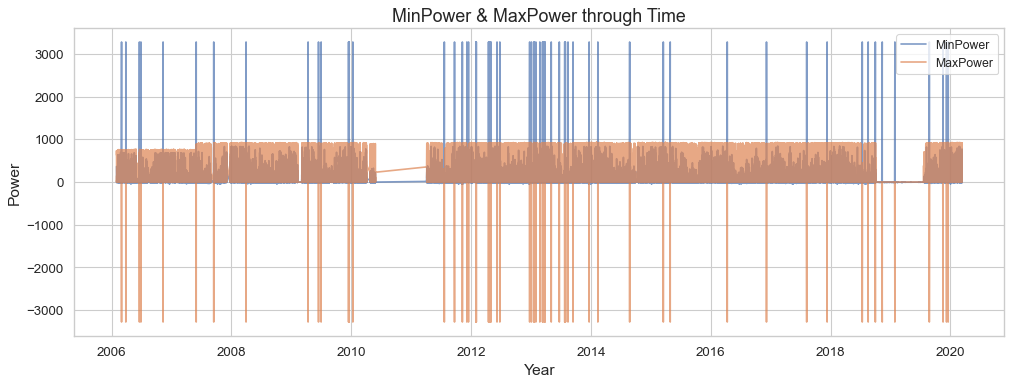

In [60]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15,5), dpi=80)

plt.plot(df['Timestamps'], df['MinPower'],
         label='MinPower', alpha=0.7)
plt.plot(df['Timestamps'], df['MaxPower'],
         label='MaxPower', alpha=0.7)


plt.xlabel('Year', fontsize=14)
plt.ylabel('Power', fontsize=14)
plt.title( 'MinPower & MaxPower through Time', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend()
plt.show()

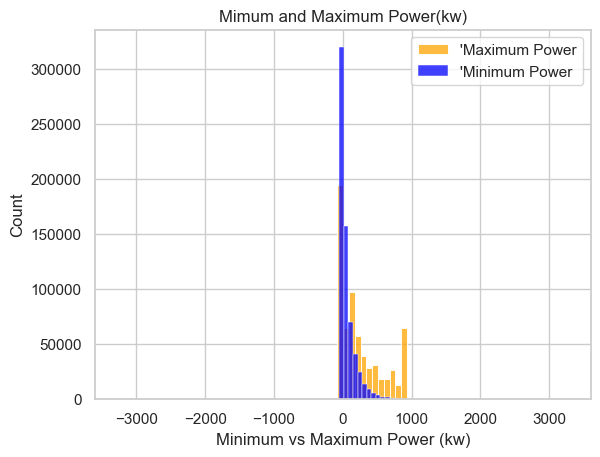

In [74]:
sns.histplot(df['MaxPower'],bins=50, color="orange",label="'Maximum Power")
sns.histplot(df['MinPower'],bins=50, color="blue",label="'Minimum Power")
plt.legend()
plt.xlabel("Minimum vs Maximum Power (kw)")
plt.ylabel("Count")
plt.title("Mimum and Maximum Power(kw)")
plt.legend()
plt.show()

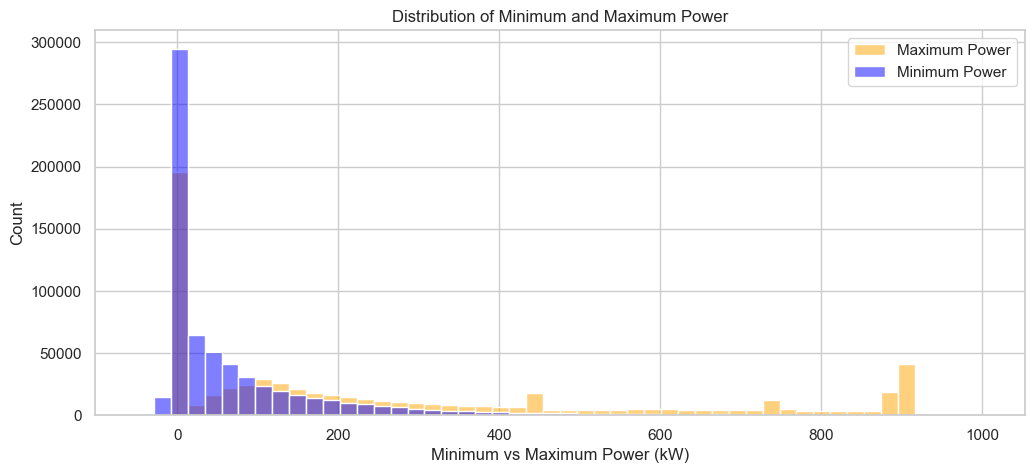

In [77]:
#NOTe: Ai was used to clean the below code ( to save on time and select reasonable bins)

plt.figure(figsize=(12,5))

sns.histplot(
    df.loc[df['MaxPower'].between(-50,1000), 'MaxPower'],
    bins=50,
    binrange=(-50,1000),
    color='orange',
    alpha=0.5,
    label='Maximum Power'
)

sns.histplot(
    df.loc[df['MinPower'].between(-50,1000), 'MinPower'],
    bins=50,
    binrange=(-50,1000),
    color='blue',
    alpha=0.5,
    label='Minimum Power'
)

plt.xlabel('Minimum vs Maximum Power (kW)')
plt.ylabel('Count')
plt.title('Distribution of Minimum and Maximum Power')
plt.legend()
plt.show()

The high power readings may indicate sensore faults( or measurement errors0.

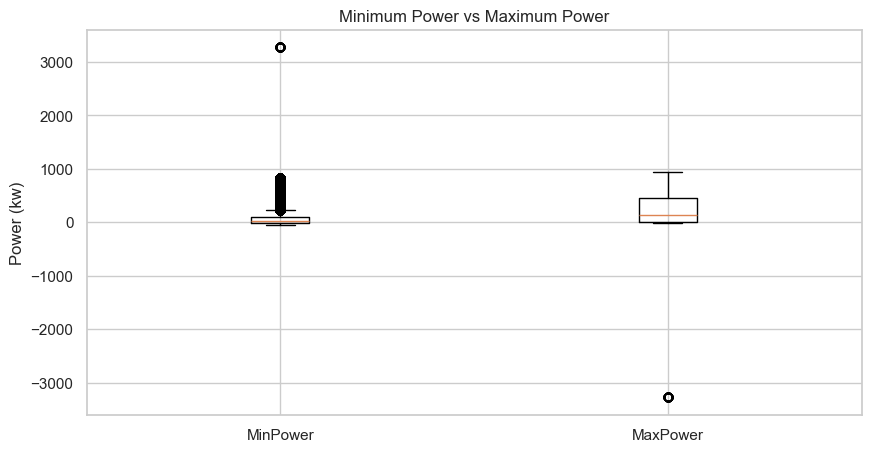

In [82]:
plt.figure(figsize=(10,5))
plt.boxplot([df['MinPower'], df['MaxPower']], tick_labels=['MinPower','MaxPower'])
plt.ylabel('Power (kw)')
plt.title('MinPower vs MaxPower')
plt.title('Minimum Power vs Maximum Power')
plt.show()


The one extremely high Minimum reading can be seen in the chart above

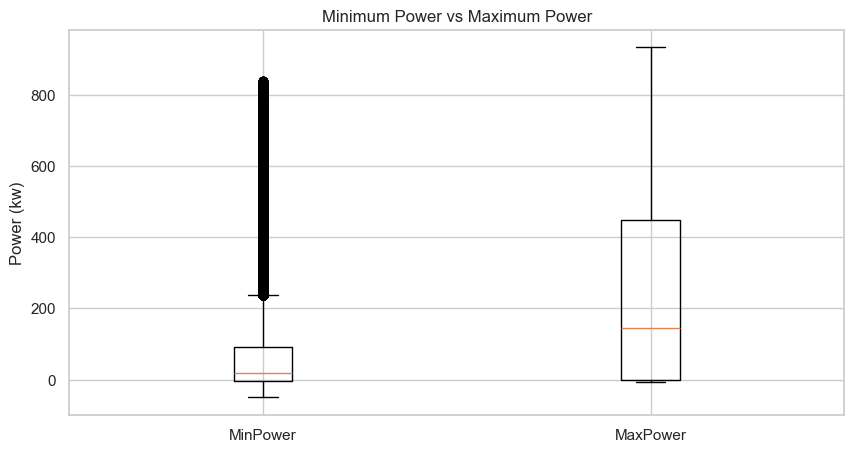

In [86]:
plt.figure(figsize=(10,5))
plt.boxplot([
    df.loc[df['MinPower'].between(-50,1000),'MinPower'],
    df.loc[df['MaxPower'].between(-50,1000),'MaxPower']]
             , tick_labels=['MinPower','MaxPower'])

plt.ylabel('Power (kw)')
plt.title('MinPower vs MaxPower')
plt.title('Minimum Power vs Maximum Power')
plt.show()


In [ ]:
there are alot of instances of high minimum power. 

In [97]:
power_lim=['Power','MinPower','MaxPower']
filtered_range =df[power_lim].where (df[power_lim].ge(-50) & df[power_lim].le(1000))
filtered_range.agg(['mean','median','max'])
           

,Power,MinPower,MaxPower
mean,165.600918,67.851056,267.816051
median,77.500000,18.400000,143.500000
max,872.300000,838.400000,933.000000


once the high readings are excluded, the mean of MinPower(67.85) is far from the median (18.4). <br>
This could indicate many nstances of high readings

### Power variation

In [99]:
df['StdDevPower'].describe()

count    653103.000000
mean         43.281565
std          50.959072
min           0.000000
25%           0.700000
50%          23.200000
75%          68.000000
max         428.400000
Name: StdDevPower, dtype: float64

The Mean (43.28kw) is not far from the median (23.2kw). but since the mean is 87% greater than the mean, there may possibly be many instances of readings that are higher than the mean.

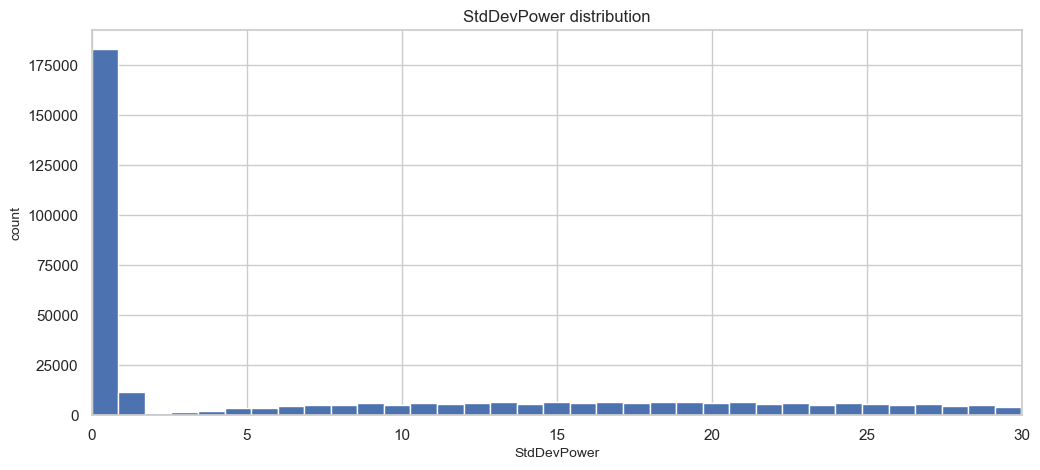

<function matplotlib.pyplot.figure(num: 'int | str | Figure | SubFigure | None' = None, figsize: 'ArrayLike | None' = None, dpi: 'float | None' = None, *, facecolor: 'ColorType | None' = None, edgecolor: 'ColorType | None' = None, frameon: 'bool' = True, FigureClass: 'type[Figure]' = <class 'matplotlib.figure.Figure'>, clear: 'bool' = False, **kwargs) -> 'Figure'>

In [107]:
plt.figure(figsize=(12,5))
plt.hist(df.StdDevPower, bins = 500,)

plt.xlim(0,30)
plt.ylabel ('count', fontsize= 10)
plt.xlabel ('StdDevPower', fontsize= 10)
plt.title('StdDevPower distribution')
plt.show()
plt.figure

most of the variations are close to 0- this indicates mostly stable power geneartion

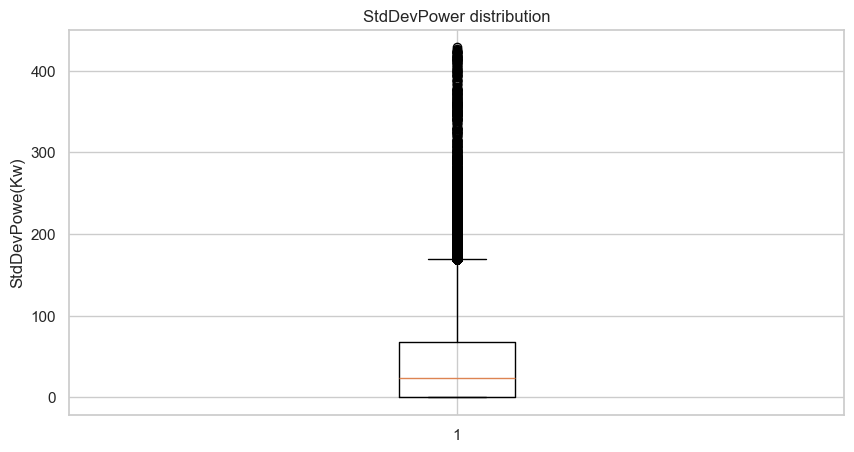

In [115]:
plt.figure(figsize=(10,5))
plt.boxplot(df.StdDevPower)
plt.ylabel ('StdDevPower', fontsize= 12)

plt.ylabel('StdDevPowe(Kw)')
plt.title('StdDevPower distribution')
plt.show()

50% of the readings fall between the 0.7(lower quantile) and 68(upper qunatile). <br>
And there are many outliers.

## Pairplot for relevant variables

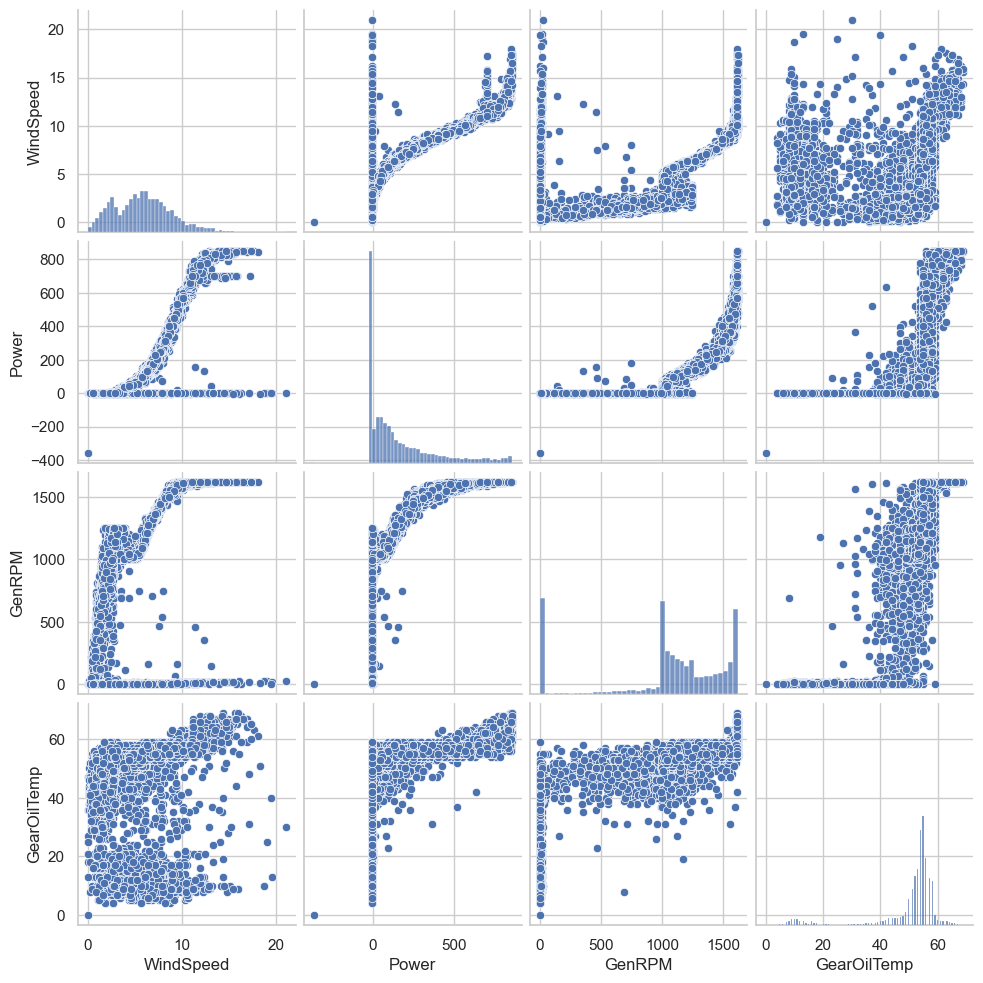

In [159]:
sns.pairplot(
    df[['WindSpeed', 'Power', 'GenRPM', 'GearOilTemp']].sample(10000, random_state=42), 
    diag_kind='hist'
)
plt.show()

In [168]:
matrix1= df[['WindSpeed', 'Power', 'GenRPM', 'GearOilTemp']].corr(method="pearson").round(2)

matrix1.style.background_gradient()

,WindSpeed,Power,GenRPM,GearOilTemp
WindSpeed,1.000000,0.720000,0.470000,0.210000
Power,0.720000,1.000000,0.670000,0.440000
GenRPM,0.470000,0.670000,1.000000,0.810000
GearOilTemp,0.210000,0.440000,0.810000,1.000000


Windspeed vs Power: there is a clear pattern that indicates a strong psoitive relationship<br>
Windspeed vs Power: there is a clear pattern that indicates a strong psoitive relationship<br>
Power vs GenRPM: there is a clear pattern that indicates a strong psoitive relationship<br>
Power vs Gearoil Temp: there is a positive relationship( not as define as the previous ones- this might mean there are other factors that affect ool temp.
GenRPM vs Gearoil Temp: higher RPM have higher temperatures.. so there might be a positive relationship. there might be a limit to RPM& temp is normally betwen 40 to 60 degrees. 

## Wind Speed and Power Generation

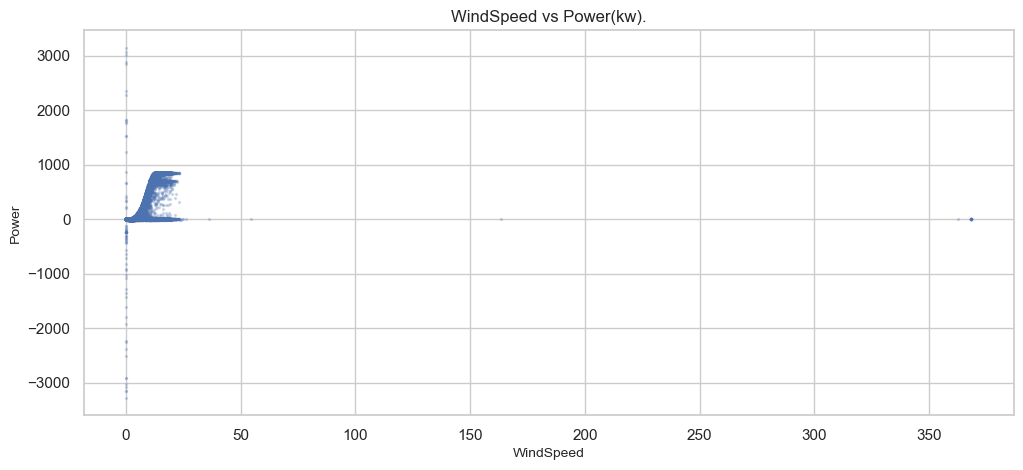

In [122]:
#Scatter Plot of Winspeed vs Power
plt.figure(figsize=(12,5))
plt.scatter(df['WindSpeed'],df['Power'], alpha=0.2, s=2)

plt.xlabel ('WindSpeed', fontsize= 10)
plt.ylabel ('Power', fontsize= 10)

plt.title('WindSpeed vs Power(kw).')
plt.show()


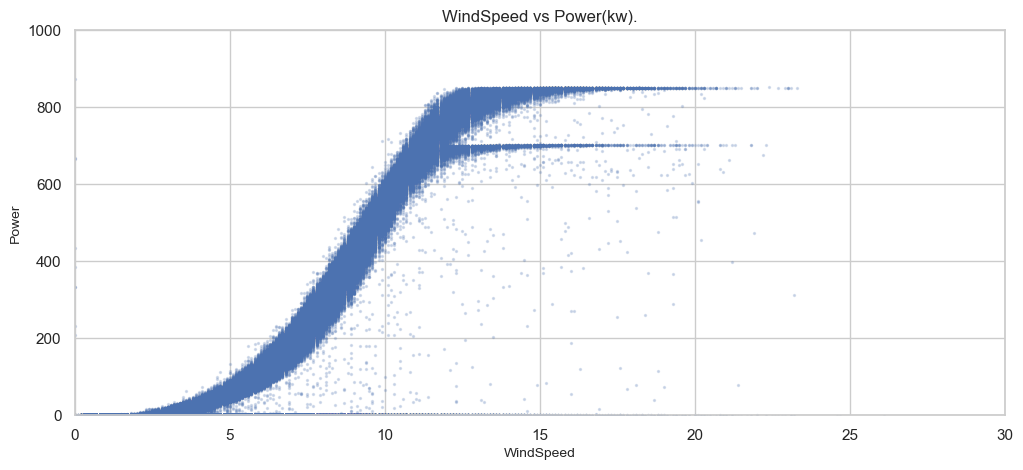

In [124]:
#Scatter Plot of Winspeed vs Power (limiting to exclude spikes)
plt.figure(figsize=(12,5))
plt.scatter(df['WindSpeed'],df['Power'], alpha=0.2, s=2)

plt.xlim(0,30)
plt.ylim(0,1000)

plt.xlabel ('WindSpeed', fontsize= 10)
plt.ylabel ('Power', fontsize= 10)

plt.title('WindSpeed vs Power(kw).')
plt.show()


The power increases steadily 4m/s and around 13 m/s and levels off around 850kw<br>
And anotheralmost flat line at around 700kw- this might suggest a specific power setting on the machine.<br>
and there are many scattered power readings from 5m/s and above wind speeds.

In [135]:
df[['WindSpeed','Power']].corr(method='pearson')

,WindSpeed,Power
WindSpeed,1.000000,0.715167
Power,0.715167,1.000000


In [136]:
df[['WindSpeed','Power']].corr(method='spearman')

,WindSpeed,Power
WindSpeed,1.000000,0.871457
Power,0.871457,1.000000


both figures Pearson(.715) and spearman (.871) indicate a strong linear realtionship between windspeed and Power

In [137]:
#Note: AI was used to generate this prompt

# Group wind speed into intervals of 1
wind_power = df.loc[
    df['WindSpeed'].between(0, 25)
].copy()

wind_power['WindSpeedBin'] = pd.cut(
    wind_power['WindSpeed'],
    bins=range(0, 27),
    include_lowest=True
)

# Average power for each wind speed interval
wind_power.groupby('WindSpeedBin', observed=True)['Power'].mean()

WindSpeedBin
(-0.001, 1.0]     -2.015581
(1.0, 2.0]        -1.271903
(2.0, 3.0]        -0.798753
(3.0, 4.0]        13.229653
(4.0, 5.0]        40.791793
(5.0, 6.0]        78.975996
(6.0, 7.0]       135.542764
(7.0, 8.0]       217.078231
(8.0, 9.0]       323.332614
(9.0, 10.0]      443.919283
(10.0, 11.0]     565.949094
(11.0, 12.0]     653.199865
(12.0, 13.0]     700.187624
(13.0, 14.0]     702.244690
(14.0, 15.0]     668.092429
(15.0, 16.0]     659.610784
(16.0, 17.0]     603.672373
(17.0, 18.0]     571.255172
(18.0, 19.0]     550.308273
(19.0, 20.0]     555.801875
(20.0, 21.0]     483.892593
(21.0, 22.0]     429.820588
(22.0, 23.0]     431.666667
(23.0, 24.0]     222.733333
(24.0, 25.0]      -2.300000
Name: Power, dtype: float64

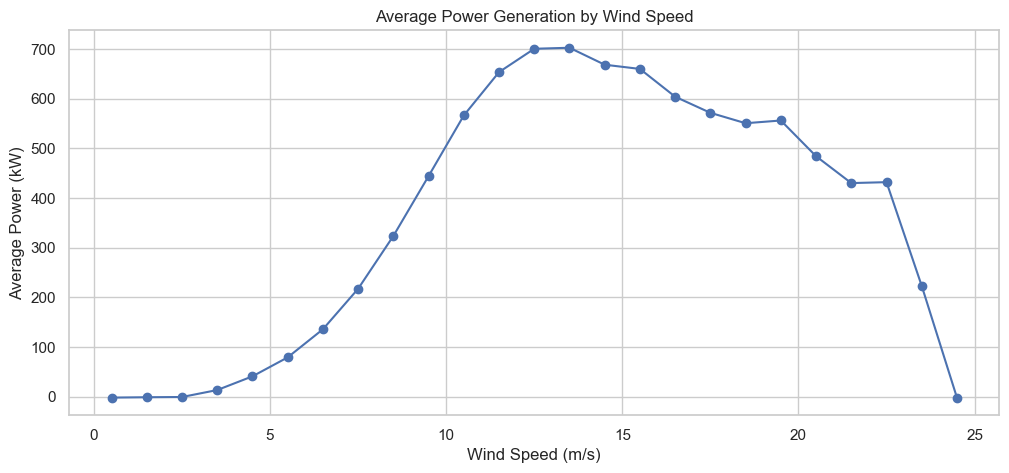

In [139]:
#Note: AI was used to generate this prompt

avg_power = wind_power.groupby(
    'WindSpeedBin', observed=True
)['Power'].mean()

plt.figure(figsize=(12,5))
plt.plot(
    [interval.mid for interval in avg_power.index],
    avg_power.values,
    marker='o'
)

plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Average Power (kW)')
plt.title('Average Power Generation by Wind Speed')
plt.grid(True)
plt.show()

this chart show power peak at around 13.5m/s and starts do decrease at higher speeds.
the decline can be further investigated/analysed

In [154]:
print('>600kw instances:', (df['Power']>600).sum())

>600kw instances: 46880


In [182]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import Plynomialfeatures
from 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

In [183]:
#Ai was usd to generate a clean code- to save on time

# Select required columns and keep chronological order
reg_df = df[['Timestamps', 'WindSpeed', 'Power']].dropna()
reg_df = reg_df.sort_values('Timestamps')

# Preliminary working range
reg_df = reg_df[
    reg_df['WindSpeed'].between(0, 25) &
    reg_df['Power'].between(-50, 1000)
]

# Split chronologically: first 80% training, last 20% testing
split = int(len(reg_df) * 0.8)


X_train = reg_df[['WindSpeed']].iloc[:split]
X_test = reg_df[['WindSpeed']].iloc[split:]

y_train = reg_df['Power'].iloc[:split]
y_test = reg_df['Power'].iloc[split:]

# Train linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print('R²:', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

R²: 0.32581131688082376
MAE: 111.35609373832995
RMSE: 160.13097573022122


32.6% variation ins test datset
MAE(Man absolute error): precitions differ from actual power by 111.36kw
root mean square error is 160kw

In [176]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

poly_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

In [177]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print('R²:', r2_score(y_test, poly_pred))
print('MAE:', mean_absolute_error(y_test, poly_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, poly_pred)))

R²: 0.405305425368211
MAE: 72.89827737078907
RMSE: 150.39438049289876


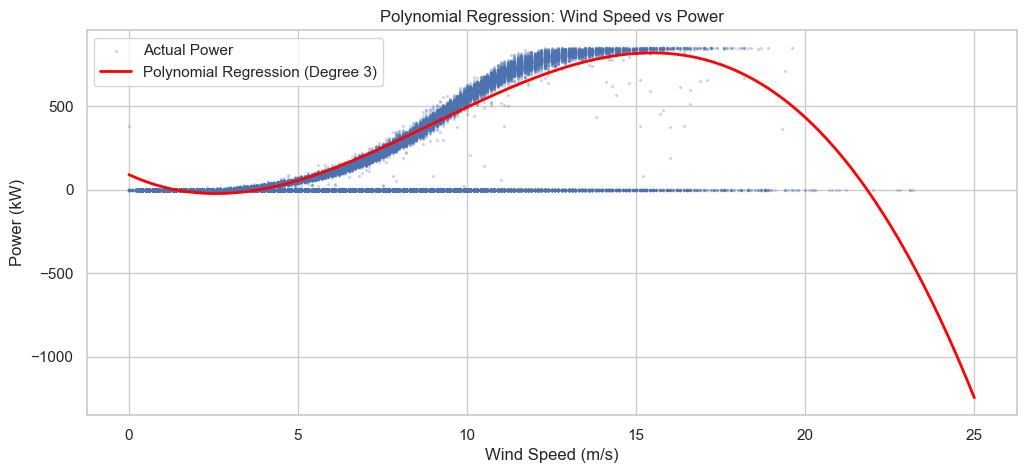

In [178]:
plt.figure(figsize=(12, 5))

plt.scatter(
    X_test['WindSpeed'], y_test,
    alpha=0.2, s=2, label='Actual Power'
)

# Generate wind speed values for a smooth curve
x_curve = np.linspace(0, 25, 300).reshape(-1, 1)
x_curve_df = pd.DataFrame(x_curve, columns=['WindSpeed'])

# Predict power along the curve
y_curve = poly_model.predict(x_curve_df)

plt.plot(
    x_curve, y_curve,
    color='red', linewidth=2,
    label='Polynomial Regression (Degree 3)'
)

plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Power (kW)')
plt.title('Polynomial Regression: Wind Speed vs Power')
plt.legend()
plt.grid(True)
plt.show()

the polynbomial regression predicts farily accurately on low wind speeds, but when the powere levels off ( from around 14m/s windspeed), the polynomial predicst lower speeds.

In [179]:
residuals = y_test - poly_pred

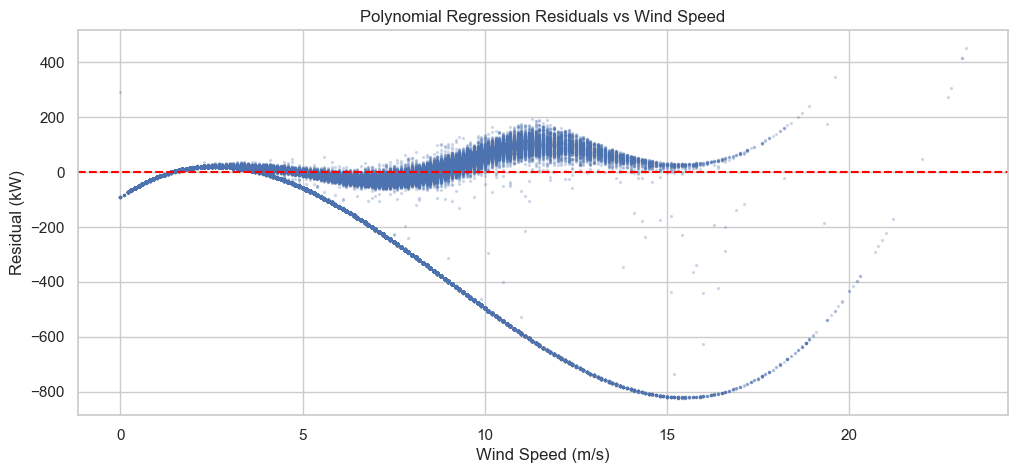

In [180]:
plt.figure(figsize=(12,5))

plt.scatter(
    X_test['WindSpeed'],
    residuals,
    alpha=0.2,
    s=2
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Residual (kW)')
plt.title('Polynomial Regression Residuals vs Wind Speed')
plt.show()

between 1 and 4m/s wind speed, the prediction is accurate<br>
at 5 to 10m/s the powere is over predicted,<br>
and above 10 m/s, the power is under predicted

In [191]:
#define variables
reg_df=df[['WindSpeed','Power']]

reg_df= reg_df[
    reg_df['WindSpeed'].between(0,25) & reg_df['Power'].between(-50,1000)]

x=reg_df[['WindSpeed']]
x=sm.add_constant(X)
y=reg_df['Power']

#fit regression model
mlr_power=sm.OLS(y,x).fit()

#fitted values
power_fitted_vals=mlr_power.fittedvalues

#residuals
power_residuals= mlr_power.resid

#standadise residuals
power_norm_residuals= mlr_power.get_influence().resid_studentized_internal


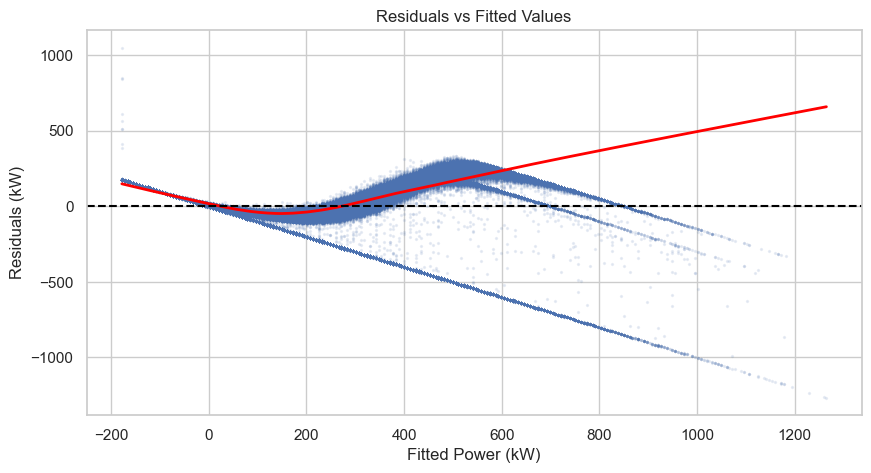

In [192]:
#Ai was used to clean this code

plt.figure(figsize=(10, 5))

sns.regplot(
    x=power_fitted_vals,
    y=power_residuals,
    ci=False,
    lowess=True,
    scatter_kws={'alpha': 0.1, 's': 2},
    line_kws={'color': 'red', 'lw': 2}
)

plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Fitted Power (kW)')
plt.ylabel('Residuals (kW)')
plt.title('Residuals vs Fitted Values')
plt.show()

-ve residual meen over prdiction and this is sizable.
there is also a larger section of under predicted values.
and there is no clear linear relationhip (unlike the correlation plots and ths earlier scatter plot)

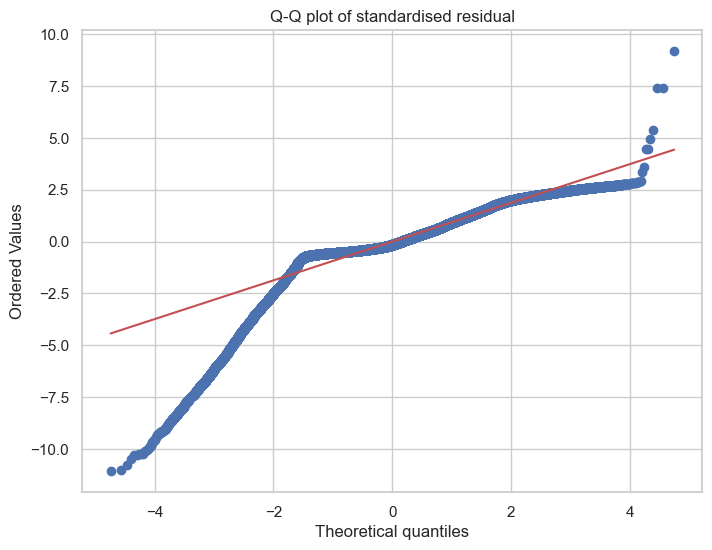

In [194]:
plt.figure(figsize=(8,6))

stats.probplot(power_norm_residuals, dist='norm',plot=plt)
plt.title('Q-Q plot of standardised residual')
plt.show()

In [2]:
!jupyter nbconvert --to webpdf "C:\Users\anyan\Wind_Turbine_Proposal_D00252218.ipynb" --output-dir "C:\Users\anyan\Downloads" --allow-chromium-download

[NbConvertApp] Converting notebook C:\Users\anyan\Wind_Turbine_Proposal_D00252218.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 56 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 2988055 bytes to C:\Users\anyan\Downloads\Wind_Turbine_Proposal_D00252218.pdf
